# 03. Referencias y validación: ¿con qué debemos comparar una predicción?

**Pregunta central:** ¿podemos reconstruir tres referencias sencillas y evaluarlas
sobre parcelas que no participaron en su ajuste, con particiones y métricas verificables?

**CRISP-DM:** modelar y evaluar. **Modo:** recalcular referencias fijas y controles.
Las medias se aprenden del entrenamiento de cada pliegue: **50 particiones × tres
referencias = 150 ajustes de referencia para la evaluación OOF**. No se crean candidatos nuevos, no se
seleccionan hiperparámetros y no se generan las 59 predicciones oficiales.

Reconstruimos las particiones del **20 de septiembre de 2026** y las referencias e
integración del **21 de septiembre**. La adaptación y comprobación de este cuaderno
son del **7 de octubre de 2026**: no constituyen un preregistro ni una ronda nueva.
No hace falta ejecutar otros cuadernos, leer una bóveda o clonar un repositorio.

**Cómo leerlo:** parcela apartada → referencia calculada con otras parcelas →
predicción → error → comparación sobre los mismos casos. La edición didáctica
del **8 de octubre** abre estas operaciones sin cambiar las recetas históricas.
Los bloques técnicos están plegados; las decisiones se estudian en las celdas visibles.

## 1. Preparar un entorno y recetas identificables

**Qué comprobamos y por qué.** Python local **3.13.13** y Colab **3.13** deben
utilizar las mismas bibliotecas requeridas. Colab administra su parche, que se registra.
`PREPARAR_COLAB = True` prepara únicamente dentro de Colab las ocho bibliotecas
faltantes o diferentes, con versiones limitadas por el perfil exportado de uv.

Si cambia una biblioteca ya cargada, el soporte pide reiniciar manualmente y ejecutar
todas las celdas. En local no instala nada. El soporte y las fuentes técnicas pueden
mantenerse contraídos; sus textos y controles tienen SHA-256.
En Colab, «Mostrar código» permite revisar el soporte y las fuentes técnicas.

In [1]:
# @title Soporte de Colab: entorno y acceso al ZIP { display-mode: "form" }
"""Preparación explícita de Colab y descarga verificada, sin cambiar cálculos científicos.

Este módulo usa la biblioteca estándar hasta que se solicita preparar Colab o descargar
el ZIP. Se incrusta completo en el notebook para no depender de un clon del proyecto.
"""

from __future__ import annotations

import hashlib
import importlib
import importlib.metadata as metadata
import os
import re
import subprocess
import sys
import tempfile
from pathlib import Path


REQUERIDOS_AUDITORIA = (
    "numpy", "pandas", "matplotlib", "pyshp", "shapely", "pyproj", "gdown", "rasterio",
)
MODULOS_DISTRIBUCIONES = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "pyshp": "shapefile", "shapely": "shapely", "pyproj": "pyproj", "gdown": "gdown",
    "pillow": "PIL", "python-dateutil": "dateutil", "beautifulsoup4": "bs4",
    "scikit-learn": "sklearn", "pysocks": "socks", "typing-extensions": "typing_extensions",
}


class ReinicioColabRequerido(RuntimeError):
    """Una instalación cambió una biblioteca que ya estaba cargada en la sesión."""

    def __init__(self, cambios: list[str], modulos_cargados: list[str]):
        self.cambios = cambios
        self.modulos_cargados = modulos_cargados
        super().__init__(
            "Las versiones se prepararon, pero ya había módulos cargados que cambiaron: "
            + ", ".join(modulos_cargados)
            + ". En Colab selecciona Entorno de ejecución > Reiniciar sesión y después "
            "Ejecutar todas. No se reinicia ni se mata la sesión automáticamente."
        )


def _perfil_fijado(perfil: str) -> dict[str, str]:
    versiones = {}
    for nombre, version in re.findall(
        r"^([A-Za-z0-9_-]+)==([^\s;]+)", perfil, flags=re.MULTILINE,
    ):
        clave = nombre.lower().replace("_", "-")
        if clave in versiones:
            raise ValueError(f"Paquete repetido en el perfil: {nombre}")
        versiones[clave] = version
    if not versiones:
        raise ValueError("El perfil de uv no contiene versiones fijadas.")
    return versiones


def versiones_requeridas(
    perfil: str, nombres: tuple[str, ...] = REQUERIDOS_AUDITORIA,
) -> dict[str, str]:
    """Lee las versiones de las raíces realmente utilizadas en esta auditoría."""
    fijadas = _perfil_fijado(perfil)
    faltantes = [nombre for nombre in nombres if nombre not in fijadas]
    if faltantes:
        raise ValueError("Faltan paquetes del cuaderno en el perfil uv: " + ", ".join(faltantes))
    return {nombre: fijadas[nombre] for nombre in nombres}


def _version_o_ausente(nombre: str, consultar_version) -> str | None:
    try:
        return consultar_version(nombre)
    except metadata.PackageNotFoundError:
        return None


def _modulo_cargado(nombre: str, modulos) -> bool:
    raiz = MODULOS_DISTRIBUCIONES.get(nombre, nombre.replace("-", "_"))
    return any(clave == raiz or clave.startswith(raiz + ".") for clave in modulos)


def _comprobar_importaciones(versiones: dict[str, str]) -> None:
    """Prueba importaciones y operaciones pequeñas; no entrena ni lee datos del reto."""
    for nombre, esperada in versiones.items():
        modulo = importlib.import_module(MODULOS_DISTRIBUCIONES.get(nombre, nombre))
        version_cargada = getattr(modulo, "__version__", None)
        if version_cargada is not None and str(version_cargada) != esperada:
            raise ReinicioColabRequerido([], [nombre])
    import numpy as np
    import pandas as pd
    from pyproj import Transformer
    from shapely.geometry import Point

    if not np.isclose(np.array([1.0, 3.0]).mean(), 2.0):
        raise RuntimeError("No pasó la comprobación mínima de NumPy.")
    if pd.DataFrame({"x": [1, 2]}).shape != (2, 1):
        raise RuntimeError("No pasó la comprobación mínima de pandas.")
    if Point(0, 0).is_empty:
        raise RuntimeError("No pasó la comprobación mínima de Shapely.")
    x, y = Transformer.from_crs(4326, 3857, always_xy=True).transform(0, 0)
    if not np.allclose([x, y], [0, 0]):
        raise RuntimeError("No pasó la comprobación mínima de PROJ.")


def _avisar_incompatibilidad_numba(informar) -> None:
    """Aviso acotado: este notebook no usa ni modifica Numba."""
    try:
        requisitos = metadata.requires("numba") or []
        from packaging.requirements import Requirement

        numpy_version = metadata.version("numpy")
        for texto in requisitos:
            requisito = Requirement(texto)
            if requisito.name.lower() != "numpy":
                continue
            if requisito.marker is not None and not requisito.marker.evaluate():
                continue
            if numpy_version not in requisito.specifier:
                informar(
                    f"Aviso del entorno de Colab: Numba declara {requisito}, pero NumPy es "
                    f"{numpy_version}. Este cuaderno no usa Numba ni lo actualiza. "
                    "La verificación cubre sus bibliotecas, no todos los paquetes de Colab."
                )
    except (metadata.PackageNotFoundError, ImportError):
        return


def preparar_colab(
    perfil: str, *, en_colab: bool, habilitar: bool = True,
    consultar_version=metadata.version, modulos=None, ejecutar=subprocess.check_call,
    informar=print, verificar_importaciones=None,
) -> dict:
    """Instala solo raíces distintas/faltantes en Colab, con dependencias restringidas por uv.

    Las funciones inyectables permiten probar instalación, versiones y reinicio sin red.
    En local no se llama a pip ni se modifica el entorno: lo prepara uv.
    """
    esperadas = versiones_requeridas(perfil)
    instaladas = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in esperadas
    }
    cambios = [f"{nombre}=={version}" for nombre, version in esperadas.items()
               if instaladas[nombre] != version]
    if not en_colab:
        informar("Entorno local: no se instala nada desde el cuaderno; se utiliza uv.")
        return {"estado": "local_sin_instalar", "cambios": [], "instaladas": instaladas,
                "reinicio_requerido": False}

    informar("Preparación de Colab: Python y paquetes se comprobarán antes de leer datos.")
    informar("Plan: " + (", ".join(cambios) if cambios else "sin instalaciones necesarias"))
    if cambios and not habilitar:
        raise RuntimeError(
            "El perfil difiere y PREPARAR_COLAB está desactivado. Actívalo y vuelve "
            "a ejecutar esta celda, o prepara manualmente las versiones impresas."
        )

    fijadas = _perfil_fijado(perfil)
    modulos = sys.modules if modulos is None else modulos
    cargados_antes = {nombre for nombre in fijadas if _modulo_cargado(nombre, modulos)}
    versiones_antes = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in cargados_antes
    }
    if cambios:
        with tempfile.TemporaryDirectory(prefix="agrocebada-colab-perfil-") as carpeta:
            restricciones = Path(carpeta) / "perfil-uv-constraints.txt"
            restricciones.write_text(perfil, encoding="utf-8")
            comando = [sys.executable, "-m", "pip", "install", "--only-binary=:all:",
                       "--disable-pip-version-check", "--constraint", str(restricciones),
                       *cambios]
            informar("Se instala únicamente el plan; dependencias necesarias limitadas por uv.")
            try:
                ejecutar(comando)
            except (subprocess.CalledProcessError, OSError) as error:
                raise RuntimeError(
                    "No se pudo preparar el perfil binario. No se ejecutará la auditoría "
                    "con otras versiones. Revisa el error de pip y reinicia la sesión "
                    "si la instalación quedó a medias."
                ) from error

        importlib.invalidate_caches()
        cargados_cambiados = sorted(
            nombre for nombre in cargados_antes
            if versiones_antes[nombre] != _version_o_ausente(nombre, consultar_version)
            or any(cambio.startswith(nombre + "==") for cambio in cambios)
        )
        if cargados_cambiados:
            raise ReinicioColabRequerido(cambios, cargados_cambiados)

    instaladas = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in esperadas
    }
    divergentes = [nombre for nombre, version in esperadas.items()
                  if instaladas[nombre] != version]
    if divergentes:
        raise RuntimeError("El perfil no coincide tras prepararlo: " + ", ".join(divergentes))
    comprobar = _comprobar_importaciones if verificar_importaciones is None else (
        verificar_importaciones
    )
    comprobar(esperadas)
    # Evita inspeccionar el entorno verdadero en pruebas con proveedores de versiones inventados.
    if consultar_version is metadata.version:
        _avisar_incompatibilidad_numba(informar)
    informar("Perfil requerido e importaciones comprobados; no se garantiza todo el entorno Colab.")
    return {"estado": "colab_instalado" if cambios else "colab_existente", "cambios": cambios,
            "instaladas": instaladas, "reinicio_requerido": False}


def validar_dataset(ruta: Path, sha256_esperado: str, bytes_esperados: int) -> Path:
    """Rechaza tamaño o huella incorrectos antes de que se abra el ZIP."""
    ruta = Path(ruta)
    if not re.fullmatch(r"[0-9a-f]{64}", sha256_esperado) or bytes_esperados <= 0:
        raise ValueError("Contrato de identidad del dataset inválido.")
    if not ruta.is_file():
        raise FileNotFoundError(f"No existe el archivo de entrada: {ruta}")
    if ruta.stat().st_size != bytes_esperados:
        raise ValueError(f"Tamaño incorrecto de {ruta.name}: se esperaban {bytes_esperados} bytes.")
    huella = hashlib.sha256()
    with ruta.open("rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b""):
            huella.update(bloque)
    if huella.hexdigest() != sha256_esperado:
        raise ValueError(f"SHA-256 incorrecto de {ruta.name}; no se usará este archivo.")
    return ruta


def obtener_dataset(
    destino: Path, *, file_id: str | None = None, sha256_esperado: str,
    bytes_esperados: int, permitir_descarga: bool, descargar=None,
) -> Path:
    """Usa caché validada o descarga explícita a temporal; publica solo bytes verificados.

    Una copia local incorrecta nunca se sustituye silenciosamente. Una descarga rechazada
    queda en cuarentena para diagnóstico; no se cambian permisos, cuentas ni credenciales.
    """
    destino = Path(destino).expanduser()
    if destino.exists():
        return validar_dataset(destino, sha256_esperado, bytes_esperados)
    if not permitir_descarga:
        raise FileNotFoundError(
            "No está el ZIP original. En local, coloca DataSet.zip en data/raw/ o indica "
            "RUTA_DATASET. La descarga solo se habilita explícitamente."
        )
    if file_id is None or not re.fullmatch(r"[A-Za-z0-9_-]{10,}", file_id):
        raise ValueError(
            "Falta el ID de Drive del ZIP original autorizado. Configura ID_DRIVE_DATASET "
            "(no el ID del notebook), o proporciona una copia local verificada."
        )
    if not re.fullmatch(r"[0-9a-f]{64}", sha256_esperado) or bytes_esperados <= 0:
        raise ValueError("Contrato de identidad del dataset inválido.")
    destino.parent.mkdir(parents=True, exist_ok=True)
    descriptor, nombre_temporal = tempfile.mkstemp(
        prefix=destino.name + ".", suffix=".part", dir=destino.parent,
    )
    os.close(descriptor)
    temporal = Path(nombre_temporal)
    try:
        if descargar is None:
            import gdown

            descargar = gdown.download
        resultado = descargar(
            id=file_id, output=str(temporal), quiet=False, use_cookies=False,
        )
        if resultado is None:
            raise RuntimeError("Drive no entregó un archivo descargable.")
        validar_dataset(temporal, sha256_esperado, bytes_esperados)
        # Mismo directorio/sistema de archivos: la creación del enlace publica el
        # archivo completo y falla atómicamente si otra ejecución ganó la carrera.
        # No usamos exists() + replace(), que permitiría sustituir una aparición
        # concurrente entre ambas operaciones.
        try:
            os.link(temporal, destino)
        except FileExistsError:
            validar_dataset(destino, sha256_esperado, bytes_esperados)
        except OSError as error:
            raise RuntimeError(
                "Este destino no permite publicar mediante enlace atómico sin reemplazo. "
                "Usa una carpeta local de la sesión; no se sobrescribirá otro archivo."
            ) from error
        temporal.unlink()
        return destino
    except Exception as error:
        if temporal.exists():
            cuarentena = temporal.with_suffix(".rechazado")
            os.replace(temporal, cuarentena)
            detalle = f" Archivo recibido conservado para revisión en {cuarentena.name}."
        else:
            detalle = ""
        raise RuntimeError(
            "La descarga no quedó publicada como DataSet.zip: comprueba enlace, permisos, "
            "cuota y coincidencia de tamaño/SHA-256." + detalle
        ) from error


In [2]:
PREPARAR_COLAB = True
import importlib.util
import sys
from pathlib import Path
try:
    EN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    EN_COLAB = False
if sys.version_info[:2] != (3, 13):
    raise RuntimeError("Local y Colab requieren Python 3.13; no se cambia el intérprete.")
REQUIREMENTS_COLAB = "affine==3.0.1\n    # via rasterio\nattrs==26.1.0\n    # via\n    #   affine\n    #   rasterio\nbeautifulsoup4==4.15.0\n    # via gdown\ncertifi==2026.7.22\n    # via\n    #   pyproj\n    #   rasterio\n    #   requests\ncharset-normalizer==3.5.2\n    # via requests\nclick==8.5.0\n    # via rasterio\ncloudpickle==3.1.2\n    # via joblib\ncolorama==0.4.6 ; sys_platform == 'win32'\n    # via tqdm\ncontourpy==1.4.0\n    # via matplotlib\ncycler==0.12.1\n    # via matplotlib\nfilelock==4.0.12\n    # via gdown\nfonttools==4.66.1\n    # via matplotlib\ngdown==5.2.2\nidna==3.20\n    # via requests\njoblib==1.6.0\n    # via scikit-learn\nkiwisolver==1.5.1\n    # via matplotlib\nmatplotlib==3.11.2\nnarwhals==2.26.0\n    # via scikit-learn\nnumpy==2.4.4\n    # via\n    #   agrocebada-uv\n    #   contourpy\n    #   matplotlib\n    #   pandas\n    #   rasterio\n    #   scikit-learn\n    #   scipy\n    #   shapely\npackaging==26.3\n    # via matplotlib\npandas==2.2.3\n    # via agrocebada-uv\npillow==12.3.0\n    # via matplotlib\npyparsing==3.3.3\n    # via\n    #   matplotlib\n    #   rasterio\npyproj==3.8.0\npyshp==3.1.6\npysocks==1.7.1\n    # via requests\npython-dateutil==2.9.0.post0\n    # via\n    #   matplotlib\n    #   pandas\npytz==2026.5\n    # via pandas\nrasterio==1.5.2\nrequests==2.34.2\n    # via gdown\nscikit-learn==1.9.1\n    # via agrocebada-uv\nscipy==1.18.0\n    # via\n    #   agrocebada-uv\n    #   scikit-learn\nshapely==2.1.2\nsix==1.17.0\n    # via python-dateutil\nsoupsieve==2.10\n    # via beautifulsoup4\nthreadpoolctl==3.7.0\n    # via scikit-learn\ntqdm==4.70.1\n    # via gdown\ntyping-extensions==4.16.0\n    # via beautifulsoup4\ntzdata==2026.5\n    # via pandas\nurllib3==2.8.0\n    # via requests\n"
VERSIONES = {'numpy': '2.4.4', 'pandas': '2.2.3', 'matplotlib': '3.11.2', 'pyshp': '3.1.6', 'shapely': '2.1.2', 'pyproj': '3.8.0', 'gdown': '5.2.2', 'rasterio': '1.5.2'}
assert hashlib.sha256(REQUIREMENTS_COLAB.encode()).hexdigest() == '8f18975fe344552700b5efe887bc0ede3128554a73f1457649652b35eb9cd95e'
preparacion_entorno = preparar_colab(REQUIREMENTS_COLAB, en_colab=EN_COLAB, habilitar=PREPARAR_COLAB)
print("Preparación:", preparacion_entorno["estado"])

Entorno local: no se instala nada desde el cuaderno; se utiliza uv.
Preparación: local_sin_instalar


In [3]:
import base64
import hashlib
import importlib.metadata as metadata
import io
import json
import platform
import types
import zlib
from datetime import datetime, timezone
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
from IPython.display import display

FECHA_EJECUCION_UTC = datetime.now(timezone.utc).isoformat()
tabla_entorno = pd.DataFrame([{"biblioteca": nombre, "esperada": version,
                              "instalada": metadata.version(nombre)} for nombre, version in VERSIONES.items()])
assert sys.version_info[:2] == (3, 13)
assert tabla_entorno.esperada.eq(tabla_entorno.instalada).all(), "Prepara el perfil requerido."
print("Python:", platform.python_version(), "| Ejecución UTC:", FECHA_EJECUCION_UTC)
display(tabla_entorno)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

Python: 3.13.13 | Ejecución UTC: 2026-10-08T06:46:00.045046+00:00


,biblioteca,esperada,instalada
0,numpy,2.4.4,2.4.4
1,pandas,2.2.3,2.2.3
2,matplotlib,3.11.2,3.11.2
3,pyshp,3.1.6,3.1.6
4,shapely,2.1.2,2.1.2
5,pyproj,3.8.0,3.8.0
6,gdown,5.2.2,5.2.2
7,rasterio,1.5.2,1.5.2


In [4]:
CONFIG_JSON = '{\n  "version_esquema": 1,\n  "id": "AGC-REFERENCIAS-03-RECONSTRUCCION",\n  "fecha_adaptacion": "2026-10-07",\n  "tipo": "reconstruccion_retrospectiva_no_preregistro",\n  "alcance": "Referencias y evaluación reproducible; sin nuevos candidatos, sin selección de hiperparámetros y sin predicciones oficiales",\n  "zip_sha256": "d74dbaba1764e026da8ce38f7f3476f80523f479a6c141827887e09326061bb5",\n  "referencias": {\n    "GLOBAL": {"regla": "media del rendimiento de entrenamiento"},\n    "MUN": {"regla": "media municipal del entrenamiento", "municipio_no_visto": "GLOBAL"},\n    "MIX": {"regla": "0.5 MUN + 0.5 IDW", "peso_municipal": 0.5, "idw_k": 20, "idw_potencia": 2, "distancia_minima_m": 1.0, "crs_distancias": "EPSG:32614", "centroide": "centroide de área en UTM14N; no promedio de vértices"}\n  },\n  "particiones": {\n    "id": "COD-CV-5x10-20260920",\n    "unidad": "parcela",\n    "externas": {"repeticiones": 10, "pliegues": 5, "semilla_historica": 20260920, "esquema_historico": "RepeatedKFold aleatoria no estratificada; se reutilizan IDs del CSV, no se regeneran"},\n    "internas": {"pliegues": 4, "semilla_historica": "20260921 + repeticion*5 + pliegue", "uso_en_este_cuaderno": "validar contención y explicar selección anidada; no seleccionar ajustes"}\n  },\n  "evaluacion": {\n    "principal_de_lectura": "FULL138 para reconstrucción histórica; no selecciona modelo final",\n    "escenarios": ["FULL138", "SEEN135"],\n    "seen": "municipio de validación presente en entrenamiento exterior; máscara definida sin valores de rendimiento, igual para todos los modelos",\n    "agregacion": "errores de cada predicción OOF, sin promediar predicciones por parcela antes de puntuar",\n    "metricas": ["RMSE", "MAE", "R2"],\n    "R2": "1 - SSE/SST respecto a media del conjunto evaluado; NaN si SST <= 1e-12",\n    "replicas_no_son_independientes": true,\n    "tol_reproduccion_predicciones_t_ha": 1e-8,\n    "equivale_al_split_fira": false\n  },\n  "insumos": {\n    "externas": {"ruta_local": "data/validacion_03/particiones_externas.csv", "sha256": "02d07dfcdb8064a4daf08b5bebc575f807ccab09ca33f27ec7dfa1a069c300ec", "bytes": 175295, "uso": "particiones", "origen": "Particiones de la demostración del 20/09/2026"},\n    "internas": {"ruta_local": "data/validacion_03/particiones_internas.csv", "sha256": "a35412fda33fcea7b379f6d95418eaaa7ebafc5b5330873613b83184cb16ab6a", "bytes": 601731, "uso": "particiones", "origen": "Particiones internas de la ronda de bloques del 21/09/2026"},\n    "oof_historico": {"ruta_local": "data/validacion_03/oof_referencias_historico.csv", "sha256": "e9768cec1165f3d7f1c8ab556201bc12c8073864c9ed5b0924c7bc00466dd6d1", "bytes": 416403, "uso": "control_de_salida", "origen": "Reconstrucción de referencias de la integración del 21/09/2026; se contrastan GLOBAL/MUN/MIX"},\n    "metricas_historicas": {"ruta_local": "data/validacion_03/metricas_globales_historicas.csv", "sha256": "d094bea2a3c033df6122213c4f1eb5cfa72599e15923443defdeff844700a3e8", "bytes": 957, "uso": "control_de_salida", "origen": "Métricas de la integración del 21/09/2026; solo control después de recalcular"}\n  }\n}\n'
assert hashlib.sha256(CONFIG_JSON.encode()).hexdigest() == 'a003431aaaa7066f66258a93238eed147e682b77ec7fd04f4320bee14badb45f'
CONFIG = json.loads(CONFIG_JSON)
display(pd.DataFrame([{"referencia": nombre, **regla} for nombre, regla in CONFIG["referencias"].items()]).fillna(""))
print("Unidad de separación:", CONFIG["particiones"]["unidad"])
print("Agregación:", CONFIG["evaluacion"]["agregacion"])

,referencia,regla,municipio_no_visto,peso_municipal,idw_k,idw_potencia,distancia_minima_m,crs_distancias,centroide
0,GLOBAL,media del rendimiento de entrenamiento,,,,,,,
1,MUN,media municipal del entrenamiento,GLOBAL,,,,,,
2,MIX,0.5 MUN + 0.5 IDW,,0.5,20.0,2.0,1.0,EPSG:32614,centroide de área en UTM14N; no promedio de vé...


Unidad de separación: parcela
Agregación: errores de cada predicción OOF, sin promediar predicciones por parcela antes de puntuar


**Qué hace el motor y dónde se explica.** Cargar código permite repetir las reglas;
no sustituye los ejemplos que siguen.

| Bloque | Responsabilidad | Recorrido visible |
| --- | --- | --- |
| Soporte de Colab | Versiones, instalación controlada y acceso al ZIP | Secciones 1–2 |
| `auditoria_01` | Integridad, lectores e identificadores | Sección 2 |
| `fuentes_02` y `fuentes_02_geo` | Catálogo, etiquetas aparte y centroides UTM | Sección 2 |
| `fuentes_02_satelite` | Dependencia del módulo de fuentes; aquí no resume satélite | No se construyen las 539 variables |
| `validacion_03` | Particiones, GLOBAL/MUN/MIX, OOF y métricas | Secciones 3–9 |

**Dos tipos de CSV incrustados.** `externas` e `internas` indican quién entrena
y quién se aparta: sí organizan el cálculo. `oof_historico` y `metricas_historicas`
son **salidas de control**, abiertas solo al final, no respuestas usadas para predecir.
Los hashes comprueban identidad, no capacidad predictiva ni ausencia de toda fuga.

In [5]:
# @title Fuentes técnicas incrustadas: auditoría, variables y validación { display-mode: "form" }
FUENTES_MODULOS = {'auditoria_01': {'source': '"""Lectores y controles del cuaderno 01; sin extracción de variables ni modelos.\n\nSe leen los archivos en memoria. Ninguna función modifica o descomprime los\noriginales en el sistema de archivos. El mismo texto se incrusta en el notebook.\n"""\n\nimport hashlib\nimport io\nimport re\nimport zipfile\nfrom pathlib import Path, PurePosixPath\n\nimport numpy as np\nimport pandas as pd\nimport shapefile\nfrom pyproj import CRS\nfrom shapely.geometry import shape\n\n\nSHA256_DATASET = "d74dbaba1764e026da8ce38f7f3476f80523f479a6c141827887e09326061bb5"\nMAX_ARCHIVO_BYTES = 256 * 1024 * 1024\nMAX_TOTAL_BYTES = 512 * 1024 * 1024\nMAX_MIEMBROS = 1000\n\n\ndef validar_zip(z):\n    """Rechaza nombres ambiguos/peligrosos y limita bytes antes de leerlos."""\n    vistos, inventario = set(), []\n    infos = z.infolist()\n    if len(infos) > MAX_MIEMBROS:\n        raise ValueError("ZIP con demasiados miembros")\n    if sum(info.file_size for info in infos) > MAX_TOTAL_BYTES:\n        raise ValueError("ZIP excede el límite total de bytes descomprimidos")\n    for info in infos:\n        nombre = info.filename\n        ruta = PurePosixPath(nombre)\n        clave = nombre.rstrip("/").casefold()\n        if (\n            "\\\\" in nombre or "\\x00" in nombre or ruta.is_absolute()\n            or ".." in ruta.parts or re.match(r"^[A-Za-z]:", nombre)\n            or not ruta.parts or clave in vistos\n        ):\n            raise ValueError(f"Ruta insegura o duplicada en ZIP: {nombre!r}")\n        vistos.add(clave)\n        if (info.external_attr >> 16) & 0o170000 == 0o120000:\n            raise ValueError(f"Enlace simbólico no admitido: {nombre}")\n        if info.file_size > MAX_ARCHIVO_BYTES:\n            raise ValueError(f"Miembro excede el límite de bytes: {nombre}")\n        if info.flag_bits & 1:\n            raise ValueError("ZIP cifrado no admitido en esta auditoría")\n    # z.read comprueba CRC; no se escriben rutas del ZIP en disco.\n    for info in infos:\n        if not info.is_dir():\n            contenido = z.read(info)\n            inventario.append({\n                "nombre": info.filename,\n                "bytes": len(contenido),\n                "sha256": hashlib.sha256(contenido).hexdigest(),\n            })\n    return inventario\n\n\ndef cargar_zip(path):\n    ruta = Path(path)\n    if ruta.stat().st_size > MAX_TOTAL_BYTES:\n        raise ValueError("Archivo de entrada demasiado grande")\n    contenido = ruta.read_bytes()\n    digest = hashlib.sha256(contenido).hexdigest()\n    if digest != SHA256_DATASET:\n        raise ValueError(f"Dataset incorrecto: SHA-256 {digest}; se detiene la lectura")\n    archivo = zipfile.ZipFile(io.BytesIO(contenido))\n    validar_zip(archivo)\n    return archivo\n\n\ndef miembro_unico(z, terminacion):\n    nombres = [i.filename for i in z.infolist()\n               if not i.is_dir() and (\n                   i.filename.endswith(terminacion) if terminacion.startswith(".")\n                   else PurePosixPath(i.filename).name == terminacion\n               )]\n    if len(nombres) != 1:\n        raise ValueError(f"Se esperaba un miembro para {terminacion!r}, hay {len(nombres)}")\n    return nombres[0]\n\n\ndef leer_csv(z, terminacion):\n    return pd.read_csv(io.BytesIO(z.read(miembro_unico(z, terminacion))), encoding="utf-8-sig")\n\n\ndef normalizar_catalogo(df):\n    """Solo elimina separadores vacíos; no imputa, redondea ni cambia etiquetas."""\n    copia = df.copy(deep=True)\n    vacias = [col for col in copia.columns if str(col).startswith("Unnamed:")]\n    if any(copia[col].notna().any() for col in vacias):\n        raise ValueError("Una columna sin nombre contiene datos; no se elimina")\n    copia = copia.drop(columns=vacias)\n    requeridas = ["ID_POLIGONO", "AREA_HA", "RENDIMIENTO_T_HA", "CONJUNTO"]\n    if list(copia.columns) != requeridas:\n        raise ValueError("Esquema de catálogo inesperado")\n    ids = copia.ID_POLIGONO\n    if ids.isna().any() or not ids.astype(str).str.fullmatch(r"AGC_\\d{3}").all():\n        raise ValueError("Identificadores vacíos o mal formados")\n    if ids.duplicated().any():\n        raise ValueError("Identificador de parcela duplicado")\n    if not copia.CONJUNTO.isin(["ENTRENAMIENTO", "PREDICCION"]).all():\n        raise ValueError("CONJUNTO desconocido")\n    for col in ["AREA_HA", "RENDIMIENTO_T_HA"]:\n        copia[col] = pd.to_numeric(copia[col], errors="raise")\n    if not np.isfinite(copia.AREA_HA).all() or (copia.AREA_HA <= 0).any():\n        raise ValueError("Área no positiva o no finita")\n    train = copia.CONJUNTO.eq("ENTRENAMIENTO")\n    if copia.loc[train, "RENDIMIENTO_T_HA"].isna().any():\n        raise ValueError("Rendimiento ausente en entrenamiento")\n    if copia.loc[~train, "RENDIMIENTO_T_HA"].notna().any():\n        raise ValueError("Etiqueta visible en PREDICCION")\n    y = copia.loc[train, "RENDIMIENTO_T_HA"]\n    if not np.isfinite(y).all() or (y <= 0).any():\n        raise ValueError("Rendimiento observado no positivo o no finito")\n    return copia\n\n\ndef validar_satelite(df):\n    copia = df.copy(deep=True)\n    requeridas = {"ID_POLIGONO", "fecha_captura", "sensor", "porcentaje_nubosidad"}\n    if not requeridas <= set(copia.columns):\n        raise ValueError("Columnas satelitales requeridas ausentes")\n    if copia[["ID_POLIGONO", "fecha_captura", "sensor"]].isna().any().any():\n        raise ValueError("ID, fecha o sensor ausente")\n    if not copia.ID_POLIGONO.astype(str).str.fullmatch(r"AGC_\\d{3}").all():\n        raise ValueError("ID satelital mal formado")\n    if copia.sensor.astype(str).str.strip().eq("").any():\n        raise ValueError("Sensor vacío")\n    if not copia.fecha_captura.astype(str).str.fullmatch(r"\\d{2}/\\d{2}/\\d{4}").all():\n        raise ValueError("Fecha satelital no tiene formato dd/mm/aaaa")\n    copia["FECHA"] = pd.to_datetime(copia.fecha_captura, format="%d/%m/%Y", errors="raise")\n    if copia.duplicated(["ID_POLIGONO", "FECHA", "sensor"]).any():\n        raise ValueError("Observación parcela-fecha-sensor duplicada")\n    nube = pd.to_numeric(copia.porcentaje_nubosidad, errors="raise")\n    presentes = nube.dropna()\n    if not np.isfinite(presentes).all() or not presentes.between(0, 100).all():\n        raise ValueError("Nubosidad fuera de 0–100 o no finita")\n    return copia\n\n\ndef leer_geometrias(z):\n    contenido = z.read(miembro_unico(z, "Parcelas_Reto_AGC_CONJUNTO_70_30.zip"))\n    with zipfile.ZipFile(io.BytesIO(contenido)) as interno:\n        validar_zip(interno)\n        lector = shapefile.Reader(\n            shp=io.BytesIO(interno.read(miembro_unico(interno, ".shp"))),\n            shx=io.BytesIO(interno.read(miembro_unico(interno, ".shx"))),\n            dbf=io.BytesIO(interno.read(miembro_unico(interno, ".dbf"))),\n            encoding="utf-8", encodingErrors="strict",\n        )\n        crs = CRS.from_wkt(interno.read(miembro_unico(interno, ".prj")).decode("utf-8"))\n        registros = list(lector.iterShapeRecords())\n        tabla = pd.DataFrame([r.record.as_dict() for r in registros]).rename(columns={\n            "ID_POLIGON": "ID_POLIGONO", "área_ha": "AREA_HA_GEOMETRIA",\n            "CONJUNTO": "CONJUNTO_GEOMETRIA",\n        })\n        geometrias = [shape(r.shape.__geo_interface__) for r in registros]\n        lector.close()\n    esperadas = {\n        "ID_POLIGONO", "AREA_HA_GEOMETRIA", "CONJUNTO_GEOMETRIA", "Estado", "Municipio", "Cultivo",\n    }\n    if set(tabla.columns) != esperadas or tabla.ID_POLIGONO.duplicated().any():\n        raise ValueError("Esquema o identificadores del shapefile inesperados")\n    if any(g.is_empty or not g.is_valid or g.geom_type not in {"Polygon", "MultiPolygon"}\n           for g in geometrias):\n        raise ValueError("Geometría inválida/vacía/no poligonal: se requiere revisión, no reparación")\n    if len(tabla) != len(geometrias):\n        raise ValueError("Geometrías y atributos no alineados")\n    return tabla, geometrias, crs\n', 'sha256': 'fd46a23c5b79639862108074d732fd2e4533c6a02f8fa7240a0bd931b28364df'}, 'fuentes_02_geo': {'source': '"""Geometría y extracción del cuaderno 02, autocontenidas para incrustar en Colab.\n\nAdaptación del 7 de octubre de 2026 de integracion_v0/agro_v0/base.py y\nraster.py, con los controles de malla, afín completa y caché de\nfortino-pruebas/v2-lluvia-octubre-validacion-comun-30sep/verificacion/nucleo_lluvia.py\n(verificación del 1 de octubre de 2026). No entrena ni consulta rendimiento.\n\nSe conserva la receta histórica: intersecciones en el CRS del ráster, áreas\nUTM14N para EPSG:4326 y áreas nativas para topografía EPSG:6372, sin\ndensificación ni ajuste de coordenadas. La media y desviación poblacional se\nnormalizan sobre área válida. frac_valida usa la suma de piezas como\ndenominador; cobertura_total y cobertura_malla son diagnósticos adicionales,\ncon área de la parcela como denominador. No se impone el umbral V2 de lluvia\na las variables históricas de topografía.\n"""\n\nfrom __future__ import annotations\n\nimport hashlib\nimport json\nimport math\nfrom collections.abc import Mapping\n\nimport numpy as np\nimport pandas as pd\nfrom pyproj import CRS, Transformer\nfrom rasterio.io import MemoryFile\nfrom shapely import force_2d, wkb\nfrom shapely.geometry import Polygon\nfrom shapely.ops import transform as geo_transform\n\n\nVERSION_GEO_02 = "v0-area-con-controles-20261007"\n\n\ndef _validar_geometria(geometria):\n    if geometria is None or geometria.is_empty or not geometria.is_valid:\n        raise ValueError("Geometría nula, vacía o inválida; no se repara automáticamente")\n    if geometria.geom_type not in ("Polygon", "MultiPolygon"):\n        raise ValueError("La parcela debe ser Polygon o MultiPolygon")\n    return force_2d(geometria)\n\n\ndef _vertices_geo(geometria):\n    poligonos = [geometria] if geometria.geom_type == "Polygon" else list(geometria.geoms)\n    partes = []\n    for poligono in poligonos:\n        partes.append(np.asarray(poligono.exterior.coords)[:, :2])\n        partes.extend(np.asarray(anillo.coords)[:, :2] for anillo in poligono.interiors)\n    return np.vstack(partes)\n\n\ndef proyectar_geometrias(geometrias, crs_origen, crs_destino):\n    """Devuelve un dict nuevo con los mismos IDs y geometrías 2D válidas."""\n    origen, destino = CRS.from_user_input(crs_origen), CRS.from_user_input(crs_destino)\n    proyectar = Transformer.from_crs(origen, destino, always_xy=True).transform\n    return {\n        identificador: _validar_geometria(geo_transform(proyectar, _validar_geometria(g)))\n        for identificador, g in geometrias.items()\n    }\n\n\ndef metadatos_geo(tabla_shp, geometrias, crs_origen):\n    """(dict de geometrías, DataFrame) con los 13 campos de base.load_geometries.\n\n    tabla_shp contiene ID_POLIGON, Estado, Municipio, Cultivo, área_ha y\n    CONJUNTO. geometrias puede ser un dict por ID o una secuencia en el orden\n    de tabla_shp. Las geometrías devueltas permanecen en crs_origen.\n    """\n    tabla = pd.DataFrame(tabla_shp).copy()\n    requeridas = ["ID_POLIGON", "Estado", "Municipio", "Cultivo", "área_ha", "CONJUNTO"]\n    faltan = set(requeridas) - set(tabla.columns)\n    if faltan:\n        raise ValueError(f"Faltan atributos del shapefile: {sorted(faltan)}")\n    if tabla.ID_POLIGON.isna().any() or tabla.ID_POLIGON.duplicated().any():\n        raise ValueError("Los IDs del shapefile deben ser únicos y no nulos")\n    if isinstance(geometrias, Mapping):\n        if set(geometrias) != set(tabla.ID_POLIGON):\n            raise ValueError("Los IDs de las geometrías y atributos difieren")\n        originales = dict(geometrias)\n    else:\n        secuencia = list(geometrias)\n        if len(secuencia) != len(tabla):\n            raise ValueError("El número de geometrías y registros difiere")\n        originales = dict(zip(tabla.ID_POLIGON, secuencia))\n    origen = CRS.from_user_input(crs_origen)\n    a_metros = Transformer.from_crs(origen, 32614, always_xy=True).transform\n    a_grados = Transformer.from_crs(32614, 4326, always_xy=True).transform\n    salida, filas = {}, []\n    for registro in tabla.to_dict("records"):\n        identificador = registro["ID_POLIGON"]\n        g = _validar_geometria(originales[identificador])\n        pts = _vertices_geo(g)\n        repetidos = int((np.abs(np.diff(pts, axis=0)).sum(axis=1) == 0).sum())\n        gm = geo_transform(a_metros, g)\n        centro = gm.centroid\n        longitud, latitud = a_grados(centro.x, centro.y)\n        salida[identificador] = g\n        filas.append(\n            {\n                "ID_POLIGONO": identificador,\n                "Estado": registro["Estado"],\n                "Municipio": registro["Municipio"],\n                "cultivo_grafia_original": registro["Cultivo"],\n                "AREA_HA_shp": registro["área_ha"],\n                "area_geom_ha": gm.area / 1e4,\n                "x_m": centro.x,\n                "y_m": centro.y,\n                "longitude": longitud,\n                "latitude": latitud,\n                "geom_valida_original": True,\n                "geom_vertices_repetidos": repetidos,\n                "CONJUNTO_shp": registro["CONJUNTO"],\n            }\n        )\n    return salida, pd.DataFrame(filas).sort_values("ID_POLIGONO").reset_index(drop=True)\n\n\ndef _crs_area_geo(crs_raster):\n    crs = CRS.from_user_input(crs_raster)\n    if crs.to_epsg() == 4326:\n        return CRS.from_epsg(32614)\n    if crs.is_projected and all(eje.unit_conversion_factor == 1 for eje in crs.axis_info[:2]):\n        return crs\n    raise ValueError("La receta requiere EPSG:4326 o un CRS proyectado en metros")\n\n\ndef _metadata_geo(src):\n    if src.crs is None:\n        raise ValueError("Ráster sin CRS")\n    if src.count != 1:\n        raise ValueError("Se requiere un ráster de una banda")\n    afin = tuple(float(v) for v in tuple(src.transform)[:6])\n    a, b, _, d, e, _ = afin\n    det = a * e - b * d\n    if not all(math.isfinite(v) for v in afin) or not math.isfinite(det) or det == 0:\n        raise ValueError("Transformada afín no finita o no invertible")\n    if src.width <= 0 or src.height <= 0:\n        raise ValueError("Dimensiones de ráster no positivas")\n    crs = CRS.from_user_input(src.crs)\n    area = _crs_area_geo(crs)\n    tags = src.tags()\n    if tags.get("AREA_OR_POINT") == "Point":\n        raise ValueError("La receta histórica requiere píxeles de área, no PixelIsPoint")\n    documento = {\n        "transform": [repr(v) for v in afin],\n        "width": src.width,\n        "height": src.height,\n        "crs": crs.to_wkt(version="WKT2_2019"),\n    }\n    huella = hashlib.sha256(json.dumps(documento, sort_keys=True).encode()).hexdigest()\n    return {\n        "transform": afin,\n        "width": src.width,\n        "height": src.height,\n        "crs_wkt": crs.to_wkt(),\n        "epsg": crs.to_epsg(),\n        "nodata": src.nodata,\n        "dtype": src.dtypes[0],\n        "count": src.count,\n        "tags": tags,\n        "tipo_pixel": tags.get("AREA_OR_POINT"),\n        "crs_area_wkt": area.to_wkt(),\n        "epsg_area": area.to_epsg(),\n        "huella_malla": huella,\n        "rotada": b != 0 or d != 0,\n    }\n\n\ndef analizar_raster(contenido_bytes):\n    """Metadatos de un GeoTIFF en memoria, incluida la huella exacta de su malla."""\n    with MemoryFile(contenido_bytes) as archivo, archivo.open() as src:\n        return _metadata_geo(src)\n\n\ndef _a_mundo_geo(afin, col, fila):\n    a, b, c, d, e, f = afin\n    return a * col + b * fila + c, d * col + e * fila + f\n\n\ndef _a_pixel_geo(afin, x, y):\n    a, b, c, d, e, f = afin\n    det = a * e - b * d\n    dx, dy = np.asarray(x, dtype=float) - c, np.asarray(y, dtype=float) - f\n    return (e * dx - b * dy) / det, (-d * dx + a * dy) / det\n\n\ndef _pesos_geo(metadata, geometria_raster):\n    g = _validar_geometria(geometria_raster)\n    crs = CRS.from_wkt(metadata["crs_wkt"])\n    crs_area = CRS.from_wkt(metadata["crs_area_wkt"])\n    a_area = (\n        (lambda x, y, z=None: (x, y))\n        if crs == crs_area\n        else Transformer.from_crs(crs, crs_area, always_xy=True).transform\n    )\n    afin = metadata["transform"]\n    u, v = _a_pixel_geo(afin, *_vertices_geo(g).T)\n    col0, col1 = math.floor(u.min()), math.floor(u.max())\n    fila0, fila1 = math.floor(v.min()), math.floor(v.max())\n    piezas = []\n    for fila in range(max(fila0, 0), min(fila1, metadata["height"] - 1) + 1):\n        for col in range(max(col0, 0), min(col1, metadata["width"] - 1) + 1):\n            esquinas = [\n                _a_mundo_geo(afin, co, fi)\n                for co, fi in [(col, fila), (col + 1, fila), (col + 1, fila + 1), (col, fila + 1)]\n            ]\n            pixel = Polygon(esquinas)\n            pieza = g.intersection(pixel)\n            if pieza.is_empty or pieza.area <= 0:\n                continue\n            area_peso = float(geo_transform(a_area, pieza).area)\n            piezas.append(\n                {\n                    "fila": fila,\n                    "col": col,\n                    "area_peso": area_peso,\n                    "area_crs": float(pieza.area),\n                    "fraccion_celda": float(pieza.area / pixel.area),\n                    "pixel": pixel,\n                    "interseccion": pieza,\n                    "esquinas": esquinas,\n                    "esquina_ul": esquinas[0],\n                    "centro": _a_mundo_geo(afin, col + 0.5, fila + 0.5),\n                }\n            )\n    centro = g.centroid\n    cu, cv = _a_pixel_geo(afin, centro.x, centro.y)\n    area_total = float(geo_transform(a_area, g).area)\n    if not math.isfinite(area_total) or area_total <= 0:\n        raise ValueError("El área de la parcela debe ser finita y positiva")\n    return {\n        "piezas": piezas,\n        "area_parcela": area_total,\n        "area_malla": float(sum(p["area_peso"] for p in piezas)),\n        "celda_centroide": (math.floor(float(cv)), math.floor(float(cu))),\n        "centroide_xy": (centro.x, centro.y),\n        "geometria_raster": g,\n    }\n\n\ndef _clave_cache_geo(metadata, geometrias, crs_geoms):\n    documento = {\n        "version": VERSION_GEO_02,\n        "malla": metadata["huella_malla"],\n        "crs_geoms": CRS.from_user_input(crs_geoms).to_wkt(version="WKT2_2019"),\n        "crs_area": CRS.from_wkt(metadata["crs_area_wkt"]).to_wkt(version="WKT2_2019"),\n    }\n    huella = hashlib.sha256(json.dumps(documento, sort_keys=True).encode())\n    for identificador in sorted(geometrias, key=str):\n        g = _validar_geometria(geometrias[identificador])\n        huella.update(\n            repr(identificador).encode() + b"\\0" + wkb.dumps(g, output_dimension=2) + b"\\0"\n        )\n    return huella.hexdigest()\n\n\ndef _valores_y_mascara_geo(src):\n    valores = src.read(1).astype(float)\n    malos = ~np.isfinite(valores) | (src.dataset_mask() == 0) | (src.read_masks(1) == 0)\n    if src.nodata is not None and np.isfinite(src.nodata):\n        malos |= valores == src.nodata\n    return valores, malos\n\n\ndef extraer_raster(contenido_bytes, geomsdict, crs_geoms, cache=None, stats=False):\n    """ID -> pond, cent, frac_valida y diagnósticos; opcionalmente min/max/std/n_validos.\n\n    El centroide del control se calcula en el CRS propio del ráster. Su celda\n    se asigna mediante floor de la afín inversa (bordes semiabiertos). La\n    caché almacena geometría/pesos; cada archivo aporta sus valores y máscara.\n    """\n    cache = {} if cache is None else cache\n    with MemoryFile(contenido_bytes) as archivo, archivo.open() as src:\n        metadata = _metadata_geo(src)\n        clave = _clave_cache_geo(metadata, geomsdict, crs_geoms)\n        if clave not in cache:\n            proyectadas = proyectar_geometrias(geomsdict, crs_geoms, metadata["crs_wkt"])\n            cache[clave] = {\n                identificador: _pesos_geo(metadata, g) for identificador, g in proyectadas.items()\n            }\n        pesos = cache[clave]\n        valores, malos = _valores_y_mascara_geo(src)\n        salida = {}\n        for identificador, datos in pesos.items():\n            validas = [\n                (float(valores[p["fila"], p["col"]]), p["area_peso"])\n                for p in datos["piezas"]\n                if not malos[p["fila"], p["col"]]\n            ]\n            den = float(sum(peso for _, peso in validas))\n            tot = datos["area_malla"]\n            pond = sum(valor * peso for valor, peso in validas) / den if den > 0 else np.nan\n            fila, col = datos["celda_centroide"]\n            dentro = 0 <= fila < src.height and 0 <= col < src.width\n            cent = float(valores[fila, col]) if dentro and not malos[fila, col] else np.nan\n            resultado = {\n                "pond": pond,\n                "cent": cent,\n                "frac_valida": den / tot if tot > 0 else np.nan,\n                "n_celdas": len(datos["piezas"]),\n                "celda_centroide": f"R{fila}_C{col}",\n                "cobertura_total": den / datos["area_parcela"],\n                "cobertura_malla": tot / datos["area_parcela"],\n            }\n            if stats:\n                v = np.asarray([valor for valor, _ in validas])\n                w = np.asarray([peso for _, peso in validas])\n                resultado.update(\n                    {\n                        "min": float(v.min()) if len(v) else np.nan,\n                        "max": float(v.max()) if len(v) else np.nan,\n                        "n_validos": len(v),\n                        "std": float(np.sqrt(np.average((v - pond) ** 2, weights=w)))\n                        if len(v)\n                        else np.nan,\n                    }\n                )\n            salida[identificador] = resultado\n        return salida\n\n\ndef piezas_parcela_raster(contenido_bytes, geometria, crs_geoms):\n    """Geometría, piezas, esquinas/centros, pesos y valores para una figura didáctica.\n\n    Devuelve dict con metadata, geometria_raster, centroide_xy,\n    celda_centroide (fila,col), area_parcela, area_malla y piezas. Cada pieza\n    incluye pixel/interseccion shapely, área-peso, coordenadas, valor,\n    valido y pesos normalizados sobre todas las piezas y sobre piezas válidas.\n    """\n    with MemoryFile(contenido_bytes) as archivo, archivo.open() as src:\n        metadata = _metadata_geo(src)\n        g = proyectar_geometrias({"parcela": geometria}, crs_geoms, metadata["crs_wkt"])["parcela"]\n        datos = _pesos_geo(metadata, g)\n        valores, malos = _valores_y_mascara_geo(src)\n        area_valida = sum(p["area_peso"] for p in datos["piezas"] if not malos[p["fila"], p["col"]])\n        for pieza in datos["piezas"]:\n            fila, col = pieza["fila"], pieza["col"]\n            valido = not bool(malos[fila, col])\n            pieza.update(\n                {\n                    "valor": float(valores[fila, col]),\n                    "valido": valido,\n                    "peso_normalizado": pieza["area_peso"] / datos["area_malla"],\n                    "peso_valido_normalizado": pieza["area_peso"] / area_valida\n                    if valido and area_valida > 0\n                    else 0.0,\n                }\n            )\n        return {"metadata": metadata, **datos}\n', 'sha256': '571d255ff9a413918133a2198177ce39bdf37d82030e334a06fef9e90942d2b1'}, 'fuentes_02_satelite': {'source': '"""Recetas satelitales autocontenidas para el cuaderno 02.\n\nAndrea: resúmenes por captura y extremos de las columnas entregadas, reconstruidos\ny contrastados el 21 de septiembre de 2026 en la integración v0. Codex: integral\nparcial por trapecios de ``reunion_utils.py``, incorporada en esa integración.\nAdaptación educativa: 7 de octubre de 2026. Se conserva la receta de v0; los\ndiagnósticos de medias mensuales explican otra agregación y quedan separados.\nEste módulo no lee archivos, no consulta etiquetas y no entrena modelos.\n"""\n\nfrom __future__ import annotations\n\nimport numpy as np\nimport pandas as pd\n\n\nPROCEDENCIA_SATELITE = {\n    "resumenes": "Andrea; reconstrucción y contraste de integración v0, 2026-09-21",\n    "integral": "Codex, reunion_utils.partial_integral; integración v0, 2026-09-21",\n    "adaptacion": "2026-10-07",\n}\nS2_IDX = [\n    "ndvi",\n    "evi",\n    "crc",\n    "mcrc",\n    "ndsvi",\n    "srndi",\n    "mra",\n    "lai",\n    "fapar",\n    "savi",\n    "ndti",\n    "sti",\n    "ndwi",\n    "endwi",\n    "msi",\n    "emsi",\n    "dswi2",\n    "dswi3",\n    "dswi4",\n    "dswi5",\n    "nddi",\n    "enddi",\n]\nSENSOR_IDX = {"S2": S2_IDX, "PL": ["ndvi", "evi", "lai", "msavi"], "LS": ["vi6t"]}\nSTATS = [\n    "media",\n    "mediana",\n    "pico_prom",\n    "doy_pico_prom",\n    "integral",\n    "dias_integ",\n    "pixmax",\n    "doy_pixmax",\n    "pixmin",\n    "std_media",\n    "n",\n]\n\n\ndef partial_integral(dates, values, max_gap_days=30):\n    """Trapecios solo entre fechas válidas separadas como máximo por el hueco indicado.\n\n    Los valores de fechas repetidas se promedian antes de integrar. No se añaden\n    puntos al inicio o al final. Sin dos fechas compatibles: área NaN, días cero.\n    El área conserva el signo del índice; no representa biomasa por definición.\n    """\n    d = pd.DataFrame({"date": pd.to_datetime(dates), "v": values}).dropna()\n    d = d.sort_values("date").groupby("date", as_index=False).v.mean()\n    if len(d) < 2:\n        return np.nan, 0.0\n    dt = np.diff(d.date.to_numpy()) / np.timedelta64(1, "D")\n    valid = (dt > 0) & (dt <= max_gap_days)\n    area = ((d.v.to_numpy()[1:] + d.v.to_numpy()[:-1]) / 2 * dt)[valid].sum()\n    days = dt[valid].sum()\n    return (float(area) if days > 0 else np.nan), float(days)\n\n\ndef eligible(d: pd.DataFrame, inicio, fin, nube_max):\n    """Ventana inclusiva; sin umbral se conserva la nubosidad desconocida.\n\n    La presencia de cada índice se comprueba después. Con un umbral, una nube\n    desconocida queda excluida porque no se puede demostrar que lo cumple.\n    """\n    w = d[d.fecha.between(pd.Timestamp(inicio), pd.Timestamp(fin))]\n    if nube_max is not None:\n        w = w[w.porcentaje_nubosidad.le(nube_max)]\n    return w\n\n\ndef lai_rule(s: pd.Series, regla: str) -> pd.Series:\n    """Reglas explícitas de v0; la configuración histórica conserva negativos."""\n    if regla == "conservar":\n        return s\n    if regla == "recortar_en_cero":\n        return s.clip(lower=0)\n    if regla == "anular_negativos":\n        return s.where(s >= 0)\n    raise ValueError(f"Regla LAI desconocida: {regla}")\n\n\ndef summarize(\n    d, sensor, idxs, inicio, fin, nube_max, prefix, max_gap=30, lai_regla="conservar", ids=None\n):\n    """Once resúmenes por índice con la misma receta y orden de columnas que v0.\n\n    La media y el pico usan *_promedio; pixmax usa *_max. La desviación media\n    resume *_std dentro de cada captura, no la dispersión temporal de la curva.\n    Sin observaciones se conservan NaN salvo n=0 y dias_integ=0.\n    """\n    w = eligible(d[d.S.eq(sensor)], inicio, fin, nube_max)\n    w = w.sort_values(["ID_POLIGONO", "fecha"])\n    ids = ids if ids is not None else sorted(d.ID_POLIGONO.unique())\n    index = pd.Index(ids, name="ID_POLIGONO")\n    columns = {}\n    for ix in idxs:\n        col, cmax, cmin, cstd = f"{ix}_promedio", f"{ix}_max", f"{ix}_min", f"{ix}_std"\n        v = w[["ID_POLIGONO", "fecha", col, cmax, cmin, cstd]].copy()\n        if ix == "lai":\n            for c in (col, cmax, cmin):\n                v[c] = lai_rule(v[c], lai_regla)\n        v = v.dropna(subset=[col])\n        g = v.groupby("ID_POLIGONO")\n        p = f"{prefix}_{ix}"\n        columns[f"{p}_media"] = g[col].mean()\n        columns[f"{p}_mediana"] = g[col].median()\n        pk = v.loc[g[col].idxmax()] if len(v) else v\n        pk = pk.set_index("ID_POLIGONO")\n        columns[f"{p}_pico_prom"] = pk[col]\n        columns[f"{p}_doy_pico_prom"] = pk.fecha.dt.dayofyear\n        integ = {k: partial_integral(q.fecha, q[col], max_gap) for k, q in g}\n        columns[f"{p}_integral"] = pd.Series(\n            {k: a for k, (a, _) in integ.items()},\n            dtype=float,\n        )\n        columns[f"{p}_dias_integ"] = pd.Series(\n            {k: b for k, (_, b) in integ.items()},\n            dtype=float,\n        ).reindex(index, fill_value=0.0)\n        vm = v.dropna(subset=[cmax])\n        px = vm.loc[vm.groupby("ID_POLIGONO")[cmax].idxmax()] if len(vm) else vm\n        px = px.set_index("ID_POLIGONO")\n        columns[f"{p}_pixmax"] = px[cmax]\n        columns[f"{p}_doy_pixmax"] = px.fecha.dt.dayofyear\n        columns[f"{p}_pixmin"] = g[cmin].min()\n        columns[f"{p}_std_media"] = g[cstd].mean()\n        columns[f"{p}_n"] = g.size().reindex(index, fill_value=0)\n    return pd.DataFrame(columns, index=index)\n\n\ndef quality(d, sensor, ref_idx, inicio, fin, nube_max, prefix, ids):\n    """Banderas v0; la nubosidad media usa toda la ventana, incluso índices ausentes.\n\n    Fracción parcial, hueco y LAI negativo usan capturas admitidas con el índice\n    de referencia disponible. No sustituyen la medición del índice faltante.\n    """\n    s = d[d.S.eq(sensor)]\n    wall = s[s.fecha.between(pd.Timestamp(inicio), pd.Timestamp(fin))]\n    w = eligible(s, inicio, fin, nube_max).dropna(subset=[f"{ref_idx}_promedio"])\n    w = w.sort_values(["ID_POLIGONO", "fecha"])\n    gall, g = wall.groupby("ID_POLIGONO"), w.groupby("ID_POLIGONO")\n    columns = {\n        f"{prefix}_q_filas_ventana": gall.size(),\n        f"{prefix}_q_con_indice": gall[f"{ref_idx}_promedio"].count(),\n        f"{prefix}_q_nube100": gall.porcentaje_nubosidad.apply(\n            lambda x: int((x == 100).sum()),\n        ),\n        f"{prefix}_q_nube_desconocida": gall.porcentaje_nubosidad.apply(\n            lambda x: int(x.isna().sum()),\n        ),\n        f"{prefix}_q_nube_media_pct": gall.porcentaje_nubosidad.mean(),\n        f"{prefix}_q_frac_nube_parcial": g.porcentaje_nubosidad.apply(\n            lambda x: float(((x > 0) & (x < 100)).mean()),\n        ),\n        f"{prefix}_q_hueco_max_dias": g.fecha.apply(lambda x: x.diff().dt.days.max()),\n    }\n    if "lai_promedio" in s.columns and sensor in ("S2", "PL"):\n        columns[f"{prefix}_q_lai_frac_neg"] = g.lai_promedio.apply(\n            lambda x: float((x < 0).mean()),\n        )\n    out = pd.DataFrame(columns, index=pd.Index(ids, name="ID_POLIGONO"))\n    return out.fillna({c: 0 for c in out.columns if c.endswith(("_filas_ventana", "_con_indice"))})\n\n\ndef _adaptar_satelite(d, sensores, ids):\n    """Adapta una copia del lector del cuaderno 01; no utiliza columnas adicionales."""\n    necesarias = {"ID_POLIGONO", "FECHA", "sensor", "porcentaje_nubosidad"}\n    if not necesarias <= set(d.columns):\n        raise ValueError("Se requiere la tabla satelital validada del cuaderno 01 (FECHA).")\n    if set(d.sensor) != set(sensores):\n        raise ValueError("Sensores inesperados o ausentes en el archivo satelital.")\n    if set(d.ID_POLIGONO) != set(ids):\n        raise ValueError("Los IDs satelitales no coinciden con el catálogo.")\n    if not pd.api.types.is_datetime64_any_dtype(d.FECHA):\n        raise ValueError("FECHA debe estar validada como fecha antes de resumir.")\n    if d.duplicated(["ID_POLIGONO", "FECHA", "sensor"]).any():\n        raise ValueError("Capturas parcela-fecha-sensor duplicadas.")\n    columnas = ["ID_POLIGONO", "sensor", "porcentaje_nubosidad", "FECHA"]\n    columnas += [c for c in d if c.endswith(("_promedio", "_max", "_min", "_std"))]\n    out = d[columnas].copy(deep=True).reset_index(drop=True)\n    out["fecha"] = out.FECHA\n    out["S"] = out.sensor.map(sensores)\n    return out\n\n\ndef construir_satelite(basico_validado, pro_validado, ids, config):\n    """Devuelve ciclo, histórico y postciclo separados, con índice ID_POLIGONO.\n\n    La configuración v0 da 320, 147 y 121 columnas respectivamente para todos\n    los IDs suministrados. No se incorpora postciclo a la base del ciclo 2025.\n    """\n    ids = list(ids)\n    if not pd.Index(ids).is_unique or not ids:\n        raise ValueError("Se requiere una lista no vacía de IDs únicos.")\n    b = _adaptar_satelite(basico_validado, {"Sentinel-2": "S2", "Landsat": "LS"}, ids)\n    p = _adaptar_satelite(pro_validado, {"Planet": "PL"}, ids)\n    src = {"S2": b, "LS": b, "PL": p}\n    ref = {"S2": "ndvi", "LS": "vi6t", "PL": "ndvi"}\n    ventana = config["ventana_objetivo"]\n    nube = config["nubosidad_max_por_sensor"]\n    gap, lai = config["integral_hueco_max_dias"], config["lai_negativos"]\n    ciclo = [\n        summarize(\n            src[s],\n            s,\n            SENSOR_IDX[s],\n            ventana["inicio"],\n            ventana["fin"],\n            nube[s],\n            f"C_{s}",\n            gap,\n            lai,\n            ids,\n        )\n        for s in src\n    ]\n    calidad = [\n        quality(src[s], s, ref[s], ventana["inicio"], ventana["fin"], nube[s], f"C_{s}", ids)\n        for s in src\n    ]\n    hist = config["historico"]\n    keep = ["media", "pico_prom", "doy_pico_prom", "integral", "dias_integ", "std_media", "n"]\n    historico = []\n    for year in hist["anios"]:\n        inicio = f"{year}-{hist[\'mes_inicio\']:02d}-01"\n        fin = pd.Timestamp(f"{year}-{hist[\'mes_fin\']:02d}-01") + pd.offsets.MonthEnd(0)\n        for sensor, indices in hist["indices"].items():\n            prefix = f"H{year}_{sensor}"\n            resumen = summarize(\n                src[sensor], sensor, indices, inicio, fin, nube[sensor], prefix, gap, lai, ids\n            )\n            historico.append(resumen[[f"{prefix}_{ix}_{stat}" for ix in indices for stat in keep]])\n    post = config["ventana_postciclo"]\n    postciclo = [\n        summarize(src[s], s, indices, post["inicio"], post["fin"], nube[s], f"P_{s}", gap, lai, ids)\n        for s, indices in config["postciclo_indices"].items()\n    ]\n    return (\n        pd.concat(ciclo + calidad, axis=1),\n        pd.concat(historico, axis=1),\n        pd.concat(postciclo, axis=1),\n    )\n\n\ndef diccionario_sat(col, config):\n    """Describe una variable satelital sin presentarla como predictor seleccionado."""\n    parts = col.split("_")\n    ventana_id, sensor = parts[:2]\n    fuentes = {"S2": "BASICO · Sentinel-2", "LS": "BASICO · Landsat", "PL": "PRO · Planet"}\n    if sensor not in fuentes or ventana_id not in ("C", "P") and not ventana_id.startswith("H20"):\n        raise ValueError(f"Variable satelital desconocida: {col}")\n    if ventana_id in ("C", "P"):\n        window = config["ventana_objetivo" if ventana_id == "C" else "ventana_postciclo"]\n        ventana = f"{window[\'inicio\']}..{window[\'fin\']}"\n        bloque = "satelite_ciclo" if ventana_id == "C" else "satelite_postciclo"\n    else:\n        hist = config["historico"]\n        ventana = (\n            f"{ventana_id[1:]}-{hist[\'mes_inicio\']:02d}..{ventana_id[1:]}-{hist[\'mes_fin\']:02d}"\n        )\n        bloque = "satelite_historico"\n    nube = config["nubosidad_max_por_sensor"][sensor]\n    filtro = (\n        f"índice presente; nubosidad ≤ {nube}; nubosidad desconocida excluida"\n        if nube is not None\n        else "índice presente (sin umbral de nubosidad)"\n    )\n    result = dict(\n        variable=col,\n        bloque=bloque,\n        rol="candidata",\n        fuente=fuentes[sensor],\n        sensor=sensor,\n        indice="",\n        ventana=ventana,\n        agregacion="",\n        filtro=filtro,\n        unidad="",\n    )\n    if parts[2] == "q":\n        flag = "_".join(parts[3:])\n        desc = {\n            "filas_ventana": ("filas de toda la ventana, con o sin índice", "filas"),\n            "con_indice": ("filas de la ventana con índice de referencia presente", "filas"),\n            "nube100": ("filas de toda la ventana con nubosidad 100 %", "filas"),\n            "nube_desconocida": ("filas de toda la ventana con nubosidad ausente", "filas"),\n            "nube_media_pct": ("media de nubosidad de toda la ventana", "%"),\n            "frac_nube_parcial": (\n                "fracción 0 < nube < 100 entre capturas admitidas con índice",\n                "fracción",\n            ),\n            "hueco_max_dias": (\n                "mayor hueco entre capturas admitidas con índice de referencia",\n                "días",\n            ),\n            "lai_frac_neg": (\n                "fracción LAI < 0 entre capturas admitidas con índice de referencia",\n                "fracción",\n            ),\n        }\n        result.update(rol="bandera_calidad", agregacion=desc[flag][0], unidad=desc[flag][1])\n        if flag in ("filas_ventana", "con_indice", "nube100", "nube_desconocida", "nube_media_pct"):\n            result["filtro"] = "toda la ventana; sin filtrar por nubosidad"\n        return result\n    indice, stat = parts[2], "_".join(parts[3:])\n    desc = {\n        "media": "media por captura de *_promedio; no pondera meses ni días",\n        "mediana": "mediana de *_promedio",\n        "pico_prom": "máximo de *_promedio (pico del promedio de parcela)",\n        "doy_pico_prom": "día del año del pico del promedio; empate: primera fecha",\n        "integral": f"trapecios con días reales, hueco ≤{config[\'integral_hueco_max_dias\']} d, sin extrapolar",\n        "dias_integ": "días cubiertos por los tramos admitidos de la integral",\n        "pixmax": "máximo de *_max (píxel extremo)",\n        "doy_pixmax": "día del año del píxel extremo máximo; empate: primera fecha",\n        "pixmin": "mínimo de *_min (píxel extremo)",\n        "std_media": "media de *_std; heterogeneidad dentro de capturas, no desviación temporal",\n        "n": "capturas admitidas con *_promedio presente",\n    }\n    unit = {\n        "doy_pico_prom": "día del año",\n        "doy_pixmax": "día del año",\n        "integral": "índice·día",\n        "dias_integ": "días",\n        "n": "observaciones",\n    }\n    result.update(\n        indice=indice,\n        agregacion=desc[stat],\n        unidad=unit.get(stat, "unidad del índice entregado"),\n        rol="pendiente_admisibilidad" if ventana_id == "P" else "candidata",\n    )\n    if indice == "lai":\n        result["filtro"] += f"; LAI negativos: {config[\'lai_negativos\']}"\n    return result\n\n\ndef diagnosticos_media_vs_tiempo(d, sensor, indice, ids, inicio, fin, nube_max=None, max_gap=30):\n    """Medias didácticas separadas de la base; devuelve diagnóstico y meses largos.\n\n    Requiere meses completos. Un mes ausente mantiene NaN en ambas medias de\n    meses; no se rellena ni se elimina una parcela. La integral dividida por\n    sus días describe solo tramos admitidos, no todos los días de la ventana.\n    """\n    inicio, fin = pd.Timestamp(inicio), pd.Timestamp(fin)\n    meses = pd.date_range(inicio, fin, freq="MS")\n    if inicio.day != 1 or not len(meses) or fin != meses[-1] + pd.offsets.MonthEnd(0):\n        raise ValueError("El diagnóstico mensual requiere una ventana de meses completos.")\n    copia = d.copy(deep=True)\n    if "fecha" not in copia:\n        copia["fecha"] = copia.FECHA\n    if "S" not in copia:\n        copia["S"] = copia.sensor.map({"Sentinel-2": "S2", "Landsat": "LS", "Planet": "PL"})\n    col = f"{indice}_promedio"\n    usados = eligible(copia[copia.S.eq(sensor)], inicio, fin, nube_max).dropna(subset=[col]).copy()\n    usados["mes"] = usados.fecha.dt.to_period("M")\n    grid = pd.MultiIndex.from_product(\n        [list(ids), meses.to_period("M")], names=["ID_POLIGONO", "mes"]\n    )\n    mensual = usados.groupby(["ID_POLIGONO", "mes"])[col].agg(media="mean", n="count").reindex(grid)\n    mensual["n"] = mensual.n.fillna(0).astype(int)\n    mensual = mensual.reset_index()\n    mensual["dias_mes"] = mensual.mes.dt.days_in_month\n    monthly = mensual.pivot(index="ID_POLIGONO", columns="mes", values="media").reindex(index=ids)\n    weights = meses.days_in_month.to_numpy()\n    complete = monthly.notna().all(axis=1)\n    out = pd.DataFrame(index=pd.Index(ids, name="ID_POLIGONO"))\n    out["media_captura"] = usados.groupby("ID_POLIGONO")[col].mean()\n    out["media_mensual_simple"] = monthly.mean(axis=1).where(complete)\n    out["media_mensual_por_dias"] = (\n        monthly.mul(weights, axis=1).sum(axis=1, min_count=len(meses)) / weights.sum()\n    )\n    out["meses_con_dato"] = monthly.notna().sum(axis=1)\n    out["meses_esperados"] = len(meses)\n    out["n_capturas"] = usados.groupby("ID_POLIGONO").size().reindex(out.index, fill_value=0)\n    integrales = {\n        k: partial_integral(q.fecha, q[col], max_gap) for k, q in usados.groupby("ID_POLIGONO")\n    }\n    out["integral"] = pd.Series({k: a for k, (a, _) in integrales.items()}, dtype=float)\n    out["dias_integrados"] = pd.Series(\n        {k: dias for k, (_, dias) in integrales.items()}, dtype=float\n    ).reindex(out.index, fill_value=0.0)\n    out["media_sobre_tramos_integrados"] = out.integral / out.dias_integrados.where(\n        out.dias_integrados.gt(0)\n    )\n    mensual["mes"] = mensual.mes.astype(str)\n    mensual["sensor"] = sensor\n    mensual["indice"] = indice\n    return out, mensual\n', 'sha256': 'e9bdcb4015b052ad13f8821d753cfcfec386b7406e1f9c15ea021aeb84c9aa29'}, 'fuentes_02': {'source': '"""Orquestación pura: originales → recetas por parcela → tabla sin rendimiento.\n\nAdaptación del 7/oct/2026 de la integración del 21/sep/2026. Las funciones reciben\nobjetos en memoria; no dependen de una bóveda, Excel, un repositorio o ficheros\nextraídos. Las funciones auxiliares también se incrustan en el notebook.\n"""\n\nfrom __future__ import annotations\n\nimport io\nimport re\nimport zipfile\n\nimport numpy as np\nimport pandas as pd\n\nfrom auditoria_01 import (\n    leer_csv,\n    leer_geometrias,\n    miembro_unico,\n    normalizar_catalogo,\n    validar_satelite,\n    validar_zip,\n)\nfrom fuentes_02_geo import analizar_raster, extraer_raster, metadatos_geo\nfrom fuentes_02_satelite import construir_satelite as construir_satelite\nfrom fuentes_02_satelite import diccionario_sat\n\nARCHIVOS_RASTER = {\n    "precipitacion": "Reto_AgroCebada_CHIRPS_Precipitacion_2022_2025.zip",\n    "temperatura": "Reto_AgroCebada_Temperatura_2022_2025_RECORTADA_CHIRPS.zip",\n    "topografia": "Reto_AgroCebada_Topografia_INEGI_CEM4.zip",\n}\n\n\ndef cargar_fuentes(zip_fuente):\n    """Lee y valida originales. Las etiquetas salen aparte, nunca hacia las recetas."""\n    catalogo = normalizar_catalogo(\n        leer_csv(zip_fuente, "ID_area_rendimiento_70_30_Reto_AgroCebada.csv")\n    )\n    basico = validar_satelite(leer_csv(zip_fuente, "Conjunto_datos_BASICO_AgroCebada2026.csv"))\n    pro = validar_satelite(leer_csv(zip_fuente, "Conjunto_datos_PRO_AgroCebada.csv"))\n    atributos, geometrias, crs = leer_geometrias(zip_fuente)\n    ids = set(catalogo.ID_POLIGONO)\n    if ids != set(atributos.ID_POLIGONO):\n        raise ValueError("IDs de catálogo y geometrías distintos")\n    for df in (basico, pro):\n        if not set(df.ID_POLIGONO) <= ids:\n            raise ValueError("ID satelital no presente en catálogo")\n    # El lector 01 ya normaliza nombres del DBF; la receta geométrica conserva\n    # el contrato de atributos originales. Renombrar no altera sus valores.\n    atributos_geo = atributos.rename(\n        columns={\n            "ID_POLIGONO": "ID_POLIGON",\n            "AREA_HA_GEOMETRIA": "área_ha",\n            "CONJUNTO_GEOMETRIA": "CONJUNTO",\n        }\n    )\n    geoms, meta = metadatos_geo(atributos_geo, geometrias, crs)\n    descripcion = (\n        catalogo.drop(columns="RENDIMIENTO_T_HA")\n        .merge(meta, on="ID_POLIGONO", validate="one_to_one")\n        .sort_values("ID_POLIGONO")\n        .reset_index(drop=True)\n    )\n    if not descripcion.CONJUNTO.eq(descripcion.CONJUNTO_shp).all():\n        raise ValueError("CONJUNTO del catálogo y geometría no coincide")\n    if not np.allclose(descripcion.AREA_HA, descripcion.AREA_HA_shp, rtol=0, atol=1e-10):\n        raise ValueError("Área entregada y área del DBF no coinciden")\n    descripcion["dif_area_pct"] = (\n        (descripcion.area_geom_ha - descripcion.AREA_HA) / descripcion.AREA_HA * 100\n    )\n    descripcion = descripcion.drop(columns=["CONJUNTO_shp", "AREA_HA_shp"])\n    etiquetas = catalogo.loc[\n        catalogo.CONJUNTO.eq("ENTRENAMIENTO"), ["ID_POLIGONO", "RENDIMIENTO_T_HA"]\n    ].copy()\n    return {\n        "metadatos": descripcion,\n        "etiquetas": etiquetas,\n        "basico": basico,\n        "pro": pro,\n        "geometrias": geoms,\n        "crs_geometrias": crs,\n    }\n\n\ndef leer_rasters(zip_fuente):\n    """Inventario y bytes verificados de 146 GeoTIFF; no escribe ZIP internos."""\n    rasters = {}\n    filas = []\n    for grupo, nombre in ARCHIVOS_RASTER.items():\n        contenido = zip_fuente.read(miembro_unico(zip_fuente, nombre))\n        with zipfile.ZipFile(io.BytesIO(contenido)) as interno:\n            validar_zip(interno)\n            for info in sorted(interno.infolist(), key=lambda item: item.filename):\n                if info.is_dir() or not info.filename.lower().endswith((".tif", ".tiff")):\n                    continue\n                archivo = info.filename.rsplit("/", 1)[-1]\n                if archivo in rasters:\n                    raise ValueError(f"GeoTIFF con nombre ambiguo: {archivo}")\n                bruto = interno.read(info)\n                rasters[archivo] = bruto\n                filas.append({"grupo": grupo, "archivo": archivo, **analizar_raster(bruto)})\n    if not filas:\n        raise ValueError("Inventario sin rásteres")\n    tabla = pd.DataFrame(filas)\n    if len(rasters) != 146:\n        raise ValueError("El inventario no contiene los 146 rásteres esperados")\n    return rasters, tabla\n\n\ndef extraer_clima(rasters, geoms, crs, cache=None):\n    """144 meses × parcelas; conserva receta histórica y añade coberturas aparte."""\n    cache = {} if cache is None else cache\n    filas = []\n    for archivo, bruto in sorted(rasters.items()):\n        captura = re.fullmatch(r"(PREC|Tmin|Tmax)_(202[2-5])_(\\d{2})\\.tif", archivo)\n        if captura is None:\n            continue\n        variable, anio, mes = captura.groups()\n        if not 1 <= int(mes) <= 12:\n            raise ValueError("Mes climático fuera de 1–12")\n        resultado = extraer_raster(bruto, geoms, crs, cache=cache)\n        for parcela, valores in resultado.items():\n            filas.append(\n                {\n                    "ID_POLIGONO": parcela,\n                    "variable": {"PREC": "prec", "Tmin": "tmin", "Tmax": "tmax"}[variable],\n                    "anio": int(anio),\n                    "mes": int(mes),\n                    "archivo": archivo,\n                    **valores,\n                }\n            )\n    if not filas:\n        raise ValueError("Clima mensual incompleto: no se encontraron rásteres climáticos")\n    tabla = pd.DataFrame(filas)\n    esperados = {\n        (v, a, m) for v in ("prec", "tmin", "tmax") for a in range(2022, 2026) for m in range(1, 13)\n    }\n    claves = set(zip(tabla.variable, tabla.anio, tabla.mes, strict=True))\n    if claves != esperados or len(tabla) != len(geoms) * 144:\n        raise ValueError("Clima mensual incompleto")\n    if tabla.duplicated(["ID_POLIGONO", "variable", "anio", "mes"]).any():\n        raise ValueError("Clave mensual duplicada")\n    return tabla\n\n\ndef resumir_clima(largo, config):\n    """Ventana de meses completos de un año; mm sumados y °C por días reales."""\n    vo, vf = (pd.Timestamp(config["ventana_objetivo"][k]) for k in ("inicio", "fin"))\n    meses = pd.date_range(vo, vf, freq="MS")\n    if (\n        not len(meses)\n        or vo.year != vf.year\n        or vo.day != 1\n        or vf != meses[-1] + pd.offsets.MonthEnd(0)\n    ):\n        raise ValueError("El clima requiere una ventana de meses completos dentro de un año")\n    mm = list(meses.month)\n    ids = sorted(largo.ID_POLIGONO.unique())\n    salida = pd.DataFrame(index=pd.Index(ids, name="ID_POLIGONO"))\n\n    def piv(variable, anio, columna="pond"):\n        filas = largo.loc[largo.variable.eq(variable) & largo.anio.eq(anio) & largo.mes.isin(mm)]\n        return filas.pivot(index="ID_POLIGONO", columns="mes", values=columna).reindex(\n            index=ids, columns=mm\n        )\n\n    anio_actual = vo.year\n    for variable, unidad in (("prec", "mm"), ("tmin", "C"), ("tmax", "C")):\n        valores = piv(variable, anio_actual)\n        for mes in mm:\n            salida[f"clim_{variable}_{anio_actual}_{mes:02d}_{unidad}"] = valores[mes]\n    salida["clim_prec_ciclo_mm"] = piv("prec", anio_actual).sum(axis=1, min_count=len(mm))\n    salida["clim_prec_ciclo_ctrl_centroide_mm"] = piv("prec", anio_actual, "cent").sum(\n        axis=1, min_count=len(mm)\n    )\n    salida["clim_prec_ciclo_dif_pond_menos_cent_mm"] = (\n        salida.clim_prec_ciclo_mm - salida.clim_prec_ciclo_ctrl_centroide_mm\n    )\n    for variable in ("tmin", "tmax"):\n        salida[f"clim_{variable}_ciclo_C"] = np.average(\n            piv(variable, anio_actual), axis=1, weights=meses.days_in_month.to_numpy()\n        )\n    salida["clim_amplitud_ciclo_C"] = salida.clim_tmax_ciclo_C - salida.clim_tmin_ciclo_C\n    for anio in config["historico"]["anios"]:\n        dias = pd.DatetimeIndex([pd.Timestamp(anio, mes, 1) for mes in mm]).days_in_month.to_numpy()\n        salida[f"clim_prec_ciclo_H{anio}_mm"] = piv("prec", anio).sum(axis=1, min_count=len(mm))\n        for variable in ("tmin", "tmax"):\n            salida[f"clim_{variable}_ciclo_H{anio}_C"] = np.average(\n                piv(variable, anio), axis=1, weights=dias\n            )\n    for variable, tag in (("prec", "prec"), ("tmin", "temp")):\n        q = largo.loc[\n            largo.variable.eq(variable) & largo.anio.eq(anio_actual) & largo.mes.eq(mm[0])\n        ].set_index("ID_POLIGONO")\n        salida[f"clim_q_n_celdas_{tag}"] = q.n_celdas\n        salida[f"clim_q_frac_area_valida_{tag}"] = q.frac_valida\n        salida[f"clim_q_celda_centroide_{tag}"] = q.celda_centroide\n    return salida\n\n\ndef extraer_topografia(rasters, geoms, crs, cache=None):\n    """Dos superficies; no calcula pendiente desde elevación ni impone cobertura nueva."""\n    cache = {} if cache is None else cache\n    filas, controles = {}, []\n    reconocidos = set()\n    for archivo, bruto in sorted(rasters.items()):\n        if re.fullmatch(r"(PREC|Tmin|Tmax)_202[2-5]_\\d{2}\\.tif", archivo):\n            continue\n        if "Elevacion" in archivo:\n            variable, unidad = "elev", "m"\n        elif "Pendiente" in archivo:\n            variable, unidad = "pend", "grados"\n        else:\n            raise ValueError(f"Ráster topográfico no identificado: {archivo}")\n        if variable in reconocidos:\n            raise ValueError(f"Ráster topográfico repetido: {variable}")\n        reconocidos.add(variable)\n        for parcela, dato in extraer_raster(bruto, geoms, crs, cache=cache, stats=True).items():\n            fila = filas.setdefault(parcela, {"ID_POLIGONO": parcela})\n            fila.update(\n                {\n                    f"topo_{variable}_media_{unidad}": dato["pond"],\n                    f"topo_{variable}_min_{unidad}": dato["min"],\n                    f"topo_{variable}_max_{unidad}": dato["max"],\n                    f"topo_{variable}_std_{unidad}": dato["std"],\n                    f"topo_{variable}_rango_{unidad}": dato["max"] - dato["min"],\n                    f"topo_{variable}_npix": dato["n_validos"],\n                    f"topo_{variable}_cobertura": dato["frac_valida"],\n                    f"topo_{variable}_ctrl_centroide_{unidad}": dato["cent"],\n                }\n            )\n            controles.append(\n                {"ID_POLIGONO": parcela, "variable": variable, "archivo": archivo, **dato}\n            )\n    if reconocidos != {"elev", "pend"}:\n        raise ValueError("Se requieren elevación y pendiente")\n    return pd.DataFrame(filas.values()).set_index("ID_POLIGONO"), pd.DataFrame(controles)\n\n\ndef describir_variable(columna, config):\n    """Diccionario de las recetas; los metadatos y controles no son predictores finales."""\n    meta = {\n        "ID_POLIGONO": ("clave", "identificador", "CSV y geometrías", "ID único; no predictor"),\n        "AREA_HA": ("candidata", "ha", "CSV de catálogo", "Área entregada"),\n        "CONJUNTO": (\n            "metadato_excluir",\n            "categoría",\n            "CSV de catálogo",\n            "Rol oficial; excluir como predictor",\n        ),\n        "Estado": ("metadato_territorial", "categoría", "Shapefile", "Estado entregado"),\n        "Municipio": ("metadato_territorial", "categoría", "Shapefile", "Municipio entregado"),\n        "cultivo_grafia_original": (\n            "metadato_excluir",\n            "texto",\n            "Shapefile",\n            "Grafía original; posible huella de procedencia",\n        ),\n        "area_geom_ha": ("control", "ha", "Polígono", "Área proyectada EPSG:32614"),\n        "dif_area_pct": (\n            "bandera_calidad",\n            "%",\n            "Polígono y catálogo",\n            "100*(área geométrica−entregada)/entregada",\n        ),\n        "x_m": ("metadato_territorial", "m", "Polígono", "Centroide de área en EPSG:32614"),\n        "y_m": ("metadato_territorial", "m", "Polígono", "Centroide de área en EPSG:32614"),\n        "longitude": (\n            "metadato_territorial",\n            "grados",\n            "Polígono",\n            "Centroide UTM reproyectado a longitud",\n        ),\n        "latitude": (\n            "metadato_territorial",\n            "grados",\n            "Polígono",\n            "Centroide UTM reproyectado a latitud",\n        ),\n        "geom_valida_original": (\n            "bandera_calidad",\n            "booleano",\n            "Polígono",\n            "Validez original GEOS; sin reparación",\n        ),\n        "geom_vertices_repetidos": (\n            "bandera_calidad",\n            "vértices",\n            "Polígono",\n            "Vértices consecutivos repetidos",\n        ),\n    }\n    if columna in meta:\n        rol, unidad, fuente, agregacion = meta[columna]\n        return dict(\n            variable=columna,\n            bloque="metadatos",\n            rol=rol,\n            unidad=unidad,\n            fuente=fuente,\n            sensor="",\n            indice="",\n            ventana="estática",\n            agregacion=agregacion,\n            filtro="",\n        )\n    if columna.startswith(("C_", "H20", "P_")):\n        return diccionario_sat(columna, config)\n    if columna.startswith("clim_"):\n        rol = (\n            "bandera_calidad"\n            if "_q_" in columna\n            else (\n                "control" if "ctrl_centroide" in columna or "dif_pond" in columna else "candidata"\n            )\n        )\n        unidad = "mm" if columna.endswith("_mm") else ("°C" if columna.endswith("_C") else "")\n        if "_q_n_celdas" in columna:\n            unidad = "celdas"\n        elif "_q_frac_area" in columna:\n            unidad = "fracción"\n        elif "_q_celda_" in columna:\n            unidad = "fila_columna"\n        periodo = (\n            f"{columna.split(\'_H\')[1][:4]}-04..10"\n            if "_H20" in columna\n            else f"{config[\'ventana_objetivo\'][\'inicio\']}..{config[\'ventana_objetivo\'][\'fin\']}"\n        )\n        agregacion = (\n            "Suma mensual"\n            if "prec_ciclo" in columna\n            else "Media ponderada por días del mes"\n            if "ciclo" in columna\n            else "Valor mensual"\n        )\n        mensual = re.fullmatch(r"clim_(?:prec|tmin|tmax)_(\\d{4})_(\\d{2})_(?:mm|C)", columna)\n        if mensual:\n            anio, mes = mensual.groups()\n            fecha = pd.Timestamp(int(anio), int(mes), 1)\n            periodo = f"{fecha.date()}..{(fecha + pd.offsets.MonthEnd(0)).date()}"\n        if columna == "clim_amplitud_ciclo_C":\n            agregacion = "Tmax del ciclo menos Tmin del ciclo"\n        elif columna == "clim_prec_ciclo_dif_pond_menos_cent_mm":\n            agregacion = "Acumulado ponderado por área menos acumulado por centroide"\n        if "_q_" in columna:\n            periodo, agregacion = "malla del primer mes del ciclo", "Control de malla/cobertura"\n        espacial = (\n            "Celda del centroide planar del ráster"\n            if "ctrl_centroide" in columna\n            else ("Áreas de intersección en EPSG:32614; normalización sobre área válida")\n        )\n        return dict(\n            variable=columna,\n            bloque="clima",\n            rol=rol,\n            fuente="GeoTIFF climáticos originales",\n            sensor="",\n            indice="",\n            ventana=periodo,\n            agregacion=f"{agregacion}; {espacial}",\n            filtro="Máscara, NoData y no finitos excluidos",\n            unidad=unidad,\n        )\n    if columna.startswith("topo_"):\n        rol = (\n            "control"\n            if "ctrl_centroide" in columna\n            else ("bandera_calidad" if columna.endswith(("npix", "cobertura")) else "candidata")\n        )\n        unidad = (\n            "m"\n            if columna.endswith("_m")\n            else (\n                "grados"\n                if columna.endswith("grados")\n                else "píxeles"\n                if columna.endswith("npix")\n                else "fracción"\n            )\n        )\n        agregacion = "Estadística zonal en CRS nativo EPSG:6372; std poblacional ponderada"\n        if "ctrl_centroide" in columna:\n            agregacion = "Valor de celda bajo el centroide planar de la parcela en EPSG:6372"\n        elif columna.endswith("cobertura"):\n            agregacion = "Área con dato válido dividida por área de intersecciones dentro de malla"\n        elif columna.endswith("npix"):\n            agregacion = "Número de celdas con intersección de área positiva y dato válido"\n        return dict(\n            variable=columna,\n            bloque="topografia",\n            rol=rol,\n            fuente="GeoTIFF topográficos originales",\n            sensor="",\n            indice="",\n            ventana="estática",\n            agregacion=agregacion,\n            filtro="Máscara, NoData y no finitos excluidos; cobertura reportada",\n            unidad=unidad,\n        )\n    raise ValueError(f"Variable sin receta: {columna}")\n\n\ndef ensamblar_variables(meta, ciclo, historico, clima, topo):\n    """No acepta ni usa rendimiento. Joins uno a uno sin imputación ni aprendizaje."""\n    piezas = [meta.set_index("ID_POLIGONO"), ciclo, historico, clima, topo]\n    ids = piezas[0].index\n    nombres = []\n    for pieza in piezas:\n        if not pieza.index.is_unique or set(pieza.index) != set(ids):\n            raise ValueError("Las fuentes no tienen los mismos IDs únicos")\n        nombres.extend(pieza.columns)\n    if len(nombres) != len(set(nombres)) or any("RENDIMIENTO" in c.upper() for c in nombres):\n        raise ValueError("Nombre duplicado o rendimiento entre las variables")\n    return pd.concat([p.reindex(ids) for p in piezas], axis=1).reset_index()\n\n\ndef comparar_referencia(calculada, referencia):\n    """Contrasta la salida histórica; no la incorpora a ninguna transformación."""\n    if list(calculada.columns) != list(referencia.columns):\n        raise ValueError("Esquema o orden de columnas distinto del control histórico")\n    if any(\n        df.ID_POLIGONO.isna().any() or not df.ID_POLIGONO.is_unique\n        for df in (calculada, referencia)\n    ):\n        raise ValueError("El control requiere IDs únicos y no nulos")\n    a, b = (df.set_index("ID_POLIGONO").sort_index() for df in (calculada, referencia))\n    if not a.index.equals(b.index):\n        raise ValueError("IDs del control histórico distintos")\n    filas = []\n    for columna in a.columns:\n        x, y = a[columna], b[columna]\n        if not x.isna().equals(y.isna()):\n            raise ValueError(f"Máscara de faltantes diferente: {columna}")\n        if pd.api.types.is_numeric_dtype(x) and pd.api.types.is_numeric_dtype(y):\n            diferencia = float((x.astype(float) - y.astype(float)).abs().max())\n            es_conteo = columna.endswith(\n                (\n                    "_n",\n                    "_npix",\n                    "_n_celdas_prec",\n                    "_n_celdas_temp",\n                    "_q_filas_ventana",\n                    "_q_con_indice",\n                    "_q_nube100",\n                    "_q_nube_desconocida",\n                )\n            ) or pd.api.types.is_bool_dtype(x)\n            tolerancia = 0.0 if es_conteo else (1e-4 if columna.startswith("topo_") else 1e-8)\n            coincide = bool(\n                np.allclose(\n                    x.astype(float), y.astype(float), rtol=0, atol=tolerancia, equal_nan=True\n                )\n            )\n        else:\n            diferencia, tolerancia = 0.0, 0.0\n            coincide = bool(\n                x.fillna("<FALTANTE>").astype(str).eq(y.fillna("<FALTANTE>").astype(str)).all()\n            )\n        filas.append(\n            {\n                "variable": columna,\n                "diferencia_maxima": diferencia,\n                "tolerancia_absoluta": tolerancia,\n                "coincide": coincide,\n            }\n        )\n    return pd.DataFrame(filas)\n', 'sha256': '013faea68c1020be4612d2c2e64456ea5fe9906fff7c0f4bdb9a17ef5a0856b8'}, 'validacion_03': {'source': '"""Reconstrucción retrospectiva de GLOBAL/MUN/MIX y evaluación OOF.\n\nAdaptación del 7/oct/2026 de integracion_v0/agro_v0/evaluacion.py y\nparticiones.py. Se conservan las referencias del 20–21/sep/2026, el orden de\nentrenamiento y np.argsort de la receta IDW original. Las particiones internas\nde ronda1/ejecutar_ronda1.py se verifican, sin seleccionar ajustes ni entrenar\ncandidatos. No se crean predicciones de las 59 parcelas sin etiqueta.\n"""\n\nfrom __future__ import annotations\n\nimport hashlib\nimport json\n\nimport numpy as np\nimport pandas as pd\n\n\nMODELOS_03 = ("GLOBAL", "MUN", "MIX")\nALIAS_HISTORICOS_03 = {\n    "Media global": "GLOBAL",\n    "Media municipal": "MUN",\n    "Municipio + IDW fijo": "MIX",\n}\nROLES_03 = {"entrenamiento", "validacion"}\nCLAVES_OOF_03 = ["modelo", "repeticion", "pliegue", "ID_POLIGONO"]\n\n\ndef _ids_03(ids):\n    valores = list(ids)\n    indice = pd.Index(valores)\n    if (\n        not valores\n        or indice.hasnans\n        or not indice.is_unique\n        or any(not isinstance(x, str) or not x.strip() for x in valores)\n    ):\n        raise ValueError("Se requieren IDs únicos, no vacíos y no nulos")\n    return set(valores)\n\n\ndef _columnas_03(tabla, columnas):\n    if not tabla.columns.is_unique:\n        raise ValueError("Columnas duplicadas")\n    faltan = set(columnas) - set(tabla.columns)\n    if faltan:\n        raise ValueError(f"Faltan columnas: {sorted(faltan)}")\n\n\ndef _enteros_03(tabla, columnas):\n    for columna in columnas:\n        s = tabla[columna]\n        if pd.api.types.is_bool_dtype(s) or not pd.api.types.is_numeric_dtype(s):\n            raise ValueError(f"{columna} requiere enteros numéricos")\n        v = s.to_numpy(dtype=float)\n        if not np.isfinite(v).all() or not np.equal(v, np.floor(v)).all() or (v < 0).any():\n            raise ValueError(f"{columna} contiene valores no enteros, negativos o no finitos")\n\n\ndef _roles_03(tabla, columnas):\n    _columnas_03(tabla, columnas + ["rol", "ID_POLIGONO"])\n    if tabla.empty or tabla.rol.isna().any() or not set(tabla.rol) <= ROLES_03:\n        raise ValueError("Particiones vacías o roles inválidos")\n    if tabla.ID_POLIGONO.isna().any():\n        raise ValueError("ID nulo en particiones")\n    _enteros_03(tabla, columnas)\n    if tabla.duplicated(columnas + ["ID_POLIGONO"]).any():\n        raise ValueError("ID duplicado o solapamiento entre entrenamiento y validación")\n\n\ndef validar_externas(externas, ids, n_repeticiones=10, n_pliegues=5):\n    """Cada ID se valida una vez por repetición; cada pliegue cubre todo el catálogo visible."""\n    esperados = _ids_03(ids)\n    _roles_03(externas, ["repeticion", "pliegue"])\n    if set(externas.ID_POLIGONO) != esperados:\n        raise ValueError("IDs externos distintos de las parcelas etiquetadas")\n    if set(externas.repeticion) != set(range(n_repeticiones)):\n        raise ValueError("Repeticiones externas incompletas o no comienzan en cero")\n    for repeticion, grupo in externas.groupby("repeticion", sort=True):\n        if set(grupo.pliegue) != set(range(n_pliegues)):\n            raise ValueError(f"Pliegues externos incompletos en repetición {repeticion}")\n        val = grupo.loc[grupo.rol.eq("validacion")]\n        if set(val.ID_POLIGONO) != esperados or not val.ID_POLIGONO.is_unique:\n            raise ValueError("Cada ID debe aparecer una vez en validación por repetición")\n    tamanos = []\n    for clave, grupo in externas.groupby(["repeticion", "pliegue"], sort=True):\n        if set(grupo.ID_POLIGONO) != esperados or set(grupo.rol) != ROLES_03:\n            raise ValueError(f"Pliegue externo {clave} incompleto o sin ambos roles")\n        tamanos.append(int(grupo.rol.eq("validacion").sum()))\n    return {\n        "repeticiones": n_repeticiones,\n        "pliegues_por_repeticion": [n_pliegues],\n        "parcelas": len(esperados),\n        "filas": len(externas),\n        "validacion_por_pliegue": sorted(set(tamanos)),\n        "n_particiones": n_repeticiones * n_pliegues,\n    }\n\n\ndef validar_internas(\n    internas, externas, ids, n_repeticiones=10, n_pliegues=5, n_pliegues_internos=4\n):\n    """Las internas contienen exactamente entrenamiento exterior y jamás su validación."""\n    validar_externas(externas, ids, n_repeticiones, n_pliegues)\n    _roles_03(internas, ["repeticion", "pliegue", "pliegue_interno"])\n    claves = set(\n        map(\n            tuple,\n            externas[["repeticion", "pliegue"]]\n            .drop_duplicates()\n            .itertuples(index=False, name=None),\n        )\n    )\n    recibidas = set(\n        map(\n            tuple,\n            internas[["repeticion", "pliegue"]]\n            .drop_duplicates()\n            .itertuples(index=False, name=None),\n        )\n    )\n    if claves != recibidas:\n        raise ValueError("Las internas no cubren exactamente todos los pliegues externos")\n    exteriores = {k: g for k, g in externas.groupby(["repeticion", "pliegue"], sort=True)}\n    for clave, grupo in internas.groupby(["repeticion", "pliegue"], sort=True):\n        exterior = exteriores[clave]\n        tr = set(exterior.loc[exterior.rol.eq("entrenamiento"), "ID_POLIGONO"])\n        va = set(exterior.loc[exterior.rol.eq("validacion"), "ID_POLIGONO"])\n        if set(grupo.ID_POLIGONO) & va:\n            raise ValueError(f"Validación externa presente en internas de {clave}")\n        if set(grupo.pliegue_interno) != set(range(n_pliegues_internos)):\n            raise ValueError(f"Pliegues internos incompletos en {clave}")\n        for interno, subgrupo in grupo.groupby("pliegue_interno"):\n            if set(subgrupo.ID_POLIGONO) != tr or set(subgrupo.rol) != ROLES_03:\n                raise ValueError(\n                    f"Interna {clave}/{interno} no contiene exactamente entrenamiento exterior"\n                )\n        validacion = grupo.loc[grupo.rol.eq("validacion")]\n        if set(validacion.ID_POLIGONO) != tr or not validacion.ID_POLIGONO.is_unique:\n            raise ValueError("Cada ID exterior de entrenamiento debe validarse una vez en internas")\n    return {\n        "particiones_externas": len(claves),\n        "pliegues_internos_por_externa": [n_pliegues_internos],\n        "filas": len(internas),\n        "contencion_ok": True,\n        "sin_validacion_externa_en_internas": True,\n    }\n\n\ndef particiones_desde_csv(externas, tabla_entrenamiento, n_repeticiones=10, n_pliegues=5):\n    """(repetición, pliegue, índices tr, índices va), manteniendo orden de la tabla original."""\n    _columnas_03(tabla_entrenamiento, ["ID_POLIGONO"])\n    validar_externas(externas, tabla_entrenamiento.ID_POLIGONO, n_repeticiones, n_pliegues)\n    posiciones = {\n        identificador: i for i, identificador in enumerate(tabla_entrenamiento.ID_POLIGONO)\n    }\n    resultado = []\n    for (r, f), grupo in externas.groupby(["repeticion", "pliegue"], sort=True):\n        tr = np.asarray(\n            sorted(posiciones[i] for i in grupo.loc[grupo.rol.eq("entrenamiento"), "ID_POLIGONO"]),\n            dtype=int,\n        )\n        va = np.asarray(\n            sorted(posiciones[i] for i in grupo.loc[grupo.rol.eq("validacion"), "ID_POLIGONO"]),\n            dtype=int,\n        )\n        resultado.append((int(r), int(f), tr, va))\n    return resultado\n\n\ndef validar_recetas_referencias(config):\n    """Impide declarar parámetros distintos de la receta fija realmente reconstruida."""\n    mix = config["referencias"]["MIX"]\n    esperado = {\n        "peso_municipal": 0.5,\n        "idw_k": 20,\n        "idw_potencia": 2,\n        "distancia_minima_m": 1.0,\n        "crs_distancias": "EPSG:32614",\n    }\n    if any(mix.get(k) != v for k, v in esperado.items()):\n        raise ValueError("La configuración MIX no coincide con la receta histórica fija")\n    if config["referencias"]["MUN"].get("municipio_no_visto") != "GLOBAL":\n        raise ValueError("La referencia municipal requiere fallback GLOBAL")\n    return True\n\n\ndef _tabla_referencia_03(tabla, entrenamiento):\n    columnas = ["Municipio", "x_m", "y_m"] + (["RENDIMIENTO_T_HA"] if entrenamiento else [])\n    _columnas_03(tabla, columnas)\n    if entrenamiento and tabla.empty:\n        raise ValueError("Entrenamiento vacío")\n    if tabla.Municipio.isna().any() or tabla.Municipio.astype(str).str.strip().eq("").any():\n        raise ValueError("Municipio ausente")\n    numericas = ["x_m", "y_m"] + (["RENDIMIENTO_T_HA"] if entrenamiento else [])\n    if not np.isfinite(tabla[numericas].to_numpy(dtype=float)).all():\n        raise ValueError("Coordenadas o etiquetas de entrenamiento no finitas")\n\n\ndef predecir_referencias(a, t):\n    """GLOBAL, MUN y MIX; ningún valor de rendimiento de t se consulta."""\n    _tabla_referencia_03(a, True)\n    _tabla_referencia_03(t, False)\n    media = a.RENDIMIENTO_T_HA.mean()\n    municipal = (\n        t.Municipio.map(a.groupby("Municipio").RENDIMIENTO_T_HA.mean()).fillna(media).to_numpy()\n    )\n    axy, txy = a[["x_m", "y_m"]].to_numpy(), t[["x_m", "y_m"]].to_numpy()\n    d = np.linalg.norm(txy[:, None, :] - axy[None, :, :], axis=2)\n    idx = np.argsort(d, axis=1)[:, : min(20, len(a))]\n    seleccion = np.take_along_axis(d, idx, axis=1)\n    pesos = 1 / np.maximum(seleccion, 1.0) ** 2\n    pesos /= pesos.sum(axis=1, keepdims=True)\n    idw = (pesos * a.RENDIMIENTO_T_HA.to_numpy()[idx]).sum(axis=1)\n    salida = {\n        "GLOBAL": np.full(len(t), media),\n        "MUN": municipal,\n        "MIX": 0.5 * municipal + 0.5 * idw,\n    }\n    if not all(np.isfinite(v).all() for v in salida.values()):\n        raise ValueError("Predicción no finita")\n    return salida\n\n\ndef construir_oof(tabla138, externas, n_repeticiones=10, n_pliegues=5):\n    """Una predicción por modelo/ID/repetición; municipio_visto usa solo pertenencia de grupos."""\n    _columnas_03(tabla138, ["ID_POLIGONO"])\n    _ids_03(tabla138.ID_POLIGONO)\n    _tabla_referencia_03(tabla138, True)\n    filas = []\n    for r, f, tr, va in particiones_desde_csv(externas, tabla138, n_repeticiones, n_pliegues):\n        a, t = tabla138.iloc[tr], tabla138.iloc[va]\n        referencias = predecir_referencias(a, t)\n        media = a.RENDIMIENTO_T_HA.mean()\n        vistos = t.Municipio.isin(set(a.Municipio)).to_numpy()\n        for modelo in MODELOS_03:\n            for i, (_, registro) in enumerate(t.iterrows()):\n                filas.append(\n                    {\n                        "modelo": modelo,\n                        "repeticion": r,\n                        "pliegue": f,\n                        "ID_POLIGONO": registro.ID_POLIGONO,\n                        "observado": registro.RENDIMIENTO_T_HA,\n                        "predicho": float(referencias[modelo][i]),\n                        "ref_media_entrenamiento": media,\n                        "n_entrenamiento": len(a),\n                        "n_validacion": len(t),\n                        "municipio_visto": bool(vistos[i]),\n                        "Municipio": registro.Municipio,\n                    }\n                )\n    resultado = pd.DataFrame(filas)\n    validar_oof(resultado, externas, n_repeticiones, n_pliegues)\n    return resultado\n\n\ndef validar_oof(oof, externas, n_repeticiones=10, n_pliegues=5):\n    """Comprueba claves exactas, observaciones consistentes, dimensiones y valores finitos."""\n    ids = externas.ID_POLIGONO.drop_duplicates()\n    validar_externas(externas, ids, n_repeticiones, n_pliegues)\n    necesarias = CLAVES_OOF_03 + [\n        "observado",\n        "predicho",\n        "ref_media_entrenamiento",\n        "n_entrenamiento",\n        "n_validacion",\n        "municipio_visto",\n        "Municipio",\n    ]\n    _columnas_03(oof, necesarias)\n    if (\n        set(oof.modelo) != set(MODELOS_03)\n        or oof[CLAVES_OOF_03].isna().any().any()\n        or oof.duplicated(CLAVES_OOF_03).any()\n    ):\n        raise ValueError("Modelos OOF inesperados, claves nulas o duplicadas")\n    _enteros_03(oof, ["repeticion", "pliegue", "n_entrenamiento", "n_validacion"])\n    if not np.isfinite(\n        oof[["observado", "predicho", "ref_media_entrenamiento"]].to_numpy(dtype=float)\n    ).all():\n        raise ValueError("Valores OOF no finitos")\n    if not pd.api.types.is_bool_dtype(oof.municipio_visto) or oof.municipio_visto.isna().any():\n        raise ValueError("municipio_visto debe ser booleano no nulo")\n    esperado = set(\n        map(\n            tuple,\n            externas.loc[externas.rol.eq("validacion"), CLAVES_OOF_03[1:]].itertuples(\n                index=False, name=None\n            ),\n        )\n    )\n    for modelo, grupo in oof.groupby("modelo"):\n        recibido = set(map(tuple, grupo[CLAVES_OOF_03[1:]].itertuples(index=False, name=None)))\n        if recibido != esperado:\n            raise ValueError(f"{modelo}: claves OOF distintas de validación externa")\n    if oof.groupby("ID_POLIGONO").observado.nunique().ne(1).any():\n        raise ValueError("Observaciones distintas para el mismo ID")\n    if (\n        oof.Municipio.isna().any()\n        or oof.Municipio.astype(str).str.strip().eq("").any()\n        or oof.groupby("ID_POLIGONO").Municipio.nunique().ne(1).any()\n    ):\n        raise ValueError("Municipio nulo o inconsistente para el mismo ID")\n    if oof.groupby(CLAVES_OOF_03[1:]).municipio_visto.nunique().ne(1).any():\n        raise ValueError("Máscaras de municipios distintos entre modelos")\n    if oof.groupby(["repeticion", "pliegue"]).ref_media_entrenamiento.nunique().ne(1).any():\n        raise ValueError("Referencia media de entrenamiento inconsistente")\n    tamanos = externas.groupby(["repeticion", "pliegue", "rol"]).size()\n    municipio_por_id = oof.drop_duplicates("ID_POLIGONO").set_index("ID_POLIGONO").Municipio\n    for (r, f), grupo in oof.groupby(["repeticion", "pliegue"]):\n        if (\n            not grupo.n_entrenamiento.eq(tamanos.loc[(r, f, "entrenamiento")]).all()\n            or not grupo.n_validacion.eq(tamanos.loc[(r, f, "validacion")]).all()\n        ):\n            raise ValueError("Dimensiones OOF distintas de su partición")\n        ids_tr = externas.loc[\n            externas.repeticion.eq(r) & externas.pliegue.eq(f) & externas.rol.eq("entrenamiento"),\n            "ID_POLIGONO",\n        ]\n        vistos = set(municipio_por_id.reindex(ids_tr))\n        esperado_visto = grupo.Municipio.isin(vistos)\n        if not grupo.municipio_visto.eq(esperado_visto).all():\n            raise ValueError("municipio_visto no coincide con municipios de entrenamiento exterior")\n    return {\n        "modelos": list(MODELOS_03),\n        "filas_por_modelo": len(esperado),\n        "filas": len(oof),\n        "parcelas": len(ids),\n        "claves_completas": True,\n        "valores_finitos": True,\n    }\n\n\ndef metricas_regresion(y, p):\n    """R² estándar con media del conjunto evaluado; SST<=1e-12 produce NaN."""\n    y, p = np.asarray(y, dtype=float), np.asarray(p, dtype=float)\n    if (\n        y.ndim != 1\n        or y.shape != p.shape\n        or not len(y)\n        or not np.isfinite(y).all()\n        or not np.isfinite(p).all()\n    ):\n        raise ValueError("Se requieren vectores finitos, no vacíos y de igual longitud")\n    error = p - y\n    den = np.sum((y - y.mean()) ** 2)\n    return {\n        "RMSE": float(np.sqrt(np.mean(error**2))),\n        "MAE": float(np.mean(np.abs(error))),\n        "R2": float(1 - np.sum(error**2) / den) if den > 1e-12 else np.nan,\n    }\n\n\ndef _escenario_03(oof, escenario):\n    if escenario == "FULL138":\n        return oof\n    if escenario != "SEEN135":\n        raise ValueError("Escenario desconocido")\n    _columnas_03(oof, ["municipio_visto"])\n    if not pd.api.types.is_bool_dtype(oof.municipio_visto) or oof.municipio_visto.isna().any():\n        raise ValueError("Máscara SEEN ausente o no booleana")\n    if oof.groupby(CLAVES_OOF_03[1:]).municipio_visto.nunique().ne(1).any():\n        raise ValueError("La máscara SEEN debe ser igual para todos los modelos")\n    return oof.loc[oof.municipio_visto]\n\n\ndef _resumir_03(oof, escenario, agrupadores):\n    datos = _escenario_03(oof, escenario)\n    _columnas_03(datos, ["modelo", "ID_POLIGONO", "observado", "predicho"] + agrupadores)\n    if datos.empty:\n        raise ValueError("Escenario sin predicciones OOF")\n    filas = []\n    for clave, grupo in datos.groupby(["modelo"] + agrupadores, sort=False):\n        clave = clave if isinstance(clave, tuple) else (clave,)\n        filas.append(\n            {\n                **dict(zip(["modelo"] + agrupadores, clave)),\n                "escenario": escenario,\n                "n_parcelas": grupo.ID_POLIGONO.nunique(),\n                "n_oof": len(grupo),\n                **metricas_regresion(grupo.observado, grupo.predicho),\n            }\n        )\n    return pd.DataFrame(filas)\n\n\ndef resumen_metricas(oof, escenario="FULL138"):\n    """Puntúa todas las predicciones OOF; no promedia predicciones ni métricas de pliegues."""\n    return _resumir_03(oof, escenario, [])\n\n\ndef por_repeticion(oof, escenario="FULL138"):\n    return _resumir_03(oof, escenario, ["repeticion"])\n\n\ndef por_municipio(oof, escenario="FULL138"):\n    return _resumir_03(oof, escenario, ["Municipio"])\n\n\nmetricas_por_repeticion = por_repeticion\nmetricas_por_municipio = por_municipio\n\n\ndef comparar_oof(actual, control, tolerancia=1e-8):\n    """Claves/observado/conteos exactos; predicciones y media a tolerancia absoluta.\n\n    Normaliza solo nombres de modelos históricos conocidos. La cuarta referencia\n    IDW sola se omite del control, nunca de la tabla calculada. El hash de bytes\n    del insumo se comprueba antes de cargarlo; aquí se informa la huella de claves.\n    """\n    if not np.isfinite(tolerancia) or tolerancia < 0:\n        raise ValueError("Tolerancia inválida")\n    control = control.copy()\n    control = control.loc[~control.modelo.eq("IDW k=20 solo")].copy()\n    control["modelo"] = control.modelo.replace(ALIAS_HISTORICOS_03)\n    columnas = CLAVES_OOF_03 + [\n        "observado",\n        "predicho",\n        "ref_media_entrenamiento",\n        "n_entrenamiento",\n        "n_validacion",\n    ]\n    for df in (actual, control):\n        _columnas_03(df, columnas)\n        if (\n            df[CLAVES_OOF_03].isna().any().any()\n            or df.duplicated(CLAVES_OOF_03).any()\n            or set(df.modelo) != set(MODELOS_03)\n        ):\n            raise ValueError("Control OOF con claves duplicadas/nulas o modelos desconocidos")\n        _enteros_03(df, ["repeticion", "pliegue", "n_entrenamiento", "n_validacion"])\n        if not np.isfinite(\n            df[["observado", "predicho", "ref_media_entrenamiento"]].to_numpy(dtype=float)\n        ).all():\n            raise ValueError("Control OOF no finito")\n    a, b = (df.set_index(CLAVES_OOF_03).sort_index() for df in (actual, control))\n    if not a.index.equals(b.index):\n        raise ValueError("Claves OOF distintas del control histórico")\n    for columna in ("observado", "n_entrenamiento", "n_validacion"):\n        if not np.array_equal(a[columna].to_numpy(), b[columna].to_numpy()):\n            raise ValueError(f"{columna} distinto del control histórico")\n    documento = [list(clave) for clave in a.index.tolist()]\n    huella = hashlib.sha256(json.dumps(documento, ensure_ascii=False).encode()).hexdigest()\n    filas = []\n    for modelo in MODELOS_03:\n        pred = float((a.loc[modelo, "predicho"] - b.loc[modelo, "predicho"]).abs().max())\n        media = float(\n            (a.loc[modelo, "ref_media_entrenamiento"] - b.loc[modelo, "ref_media_entrenamiento"])\n            .abs()\n            .max()\n        )\n        filas.append(\n            {\n                "modelo": modelo,\n                "n_oof": len(a.loc[modelo]),\n                "max_abs_dif_predicho": pred,\n                "max_abs_dif_ref": media,\n                "tolerancia": tolerancia,\n                "coincide": pred <= tolerancia and media <= tolerancia,\n                "sha256_claves": huella,\n            }\n        )\n    return pd.DataFrame(filas)\n', 'sha256': 'ccd5d233ed44a0f176e092a5c4e5f1a88f82961fc3c35ccd203faa59b8034adf'}}
for nombre, registro in FUENTES_MODULOS.items():
    assert hashlib.sha256(registro["source"].encode()).hexdigest() == registro["sha256"]
    modulo = types.ModuleType(nombre)
    modulo.__file__ = "<notebook03/" + nombre + ".py>"
    sys.modules[nombre] = modulo
    exec(compile(registro["source"], modulo.__file__, "exec"), modulo.__dict__)
auditoria = sys.modules["auditoria_01"]
fuentes02 = sys.modules["fuentes_02"]
validacion = sys.modules["validacion_03"]
SHA256_DATASET = auditoria.SHA256_DATASET
assert validacion.validar_recetas_referencias(CONFIG)

In [6]:
# @title Particiones y controles históricos: integridad de los insumos { display-mode: "form" }
INSUMOS_INCRUSTADOS = {'externas': {'bytes_zlib_base64': '...', 'sha256': '02d07dfcdb8064a4daf08b5bebc575f807ccab09ca33f27ec7dfa1a069c300ec', 'bytes': 175295, 'uso': 'particiones', 'origen': 'Particiones de la demostración del 20/09/2026'}, 'internas': {'bytes_zlib_base64': '...', 'sha256': 'a35412fda33fcea7b379f6d95418eaaa7ebafc5b5330873613b83184cb16ab6a', 'bytes': 601731, 'uso': 'particiones', 'origen': 'Particiones internas de la ronda de bloques del 21/09/2026'}, 'oof_historico': {'bytes_zlib_base64': '...', 'sha256': 'e9768cec1165f3d7f1c8ab556201bc12c8073864c9ed5b0924c7bc00466dd6d1', 'bytes': 416403, 'uso': 'control_de_salida', 'origen': 'Reconstrucción de referencias de la integración del 21/09/2026; se contrastan GLOBAL/MUN/MIX'}, 'metricas_historicas': {'bytes_zlib_base64': 'eNpdkjtv20AQhHv/CvVRjH3cvooUAZIihRunSCkwNm3QkURBioP8/MyRKWQDIngc3e59M3uH+XHcz9vj7jScH8b9cMFynp+293ffv+6G5/PraXict3efrz7u5c36z2V3GB+nYTcef5/H43CYsJivtvRO647TfhqfX8fL0u+dhE7vlV54Hk+7w3S8+hj+3tz1jZvn/fxz2G9Zsz+0pdu01sQ5NTkqHUqYVjVR4kqL5O1HuiU2alIEpThcRLFxLSfWFtpUU/Fa6zNKEw2drMVSj0PwxdW0jMvElloutaBmzdi5FqmKkjmk2KzkP/bh9Tg9TKe35IZtqGbRdI+FSBXsDUCOHxAguVp6s1IgOVsH9MZwTMHsSukdBS7KMozKTQqe116eqeaVwl1xCXRPyxQVJl3qBKI4tRDhXKgygr0pgcMTDlb2ad582Hz78mPzNL3M1zYaOJtJw1soM/oItHF0QMgdf0F0J0QDG8WNuWSR4EsDOpwg9t4tGzgUPhDtOiY0cwpo2nCOctfclEgaiSOMaL5U4gDFGn/pWmlg0PAgIrckuen8vz4JbS7z/o0JIwSKKVYgrkY9ZQWdGYaOyeKoJcCGUQEeJ8Bu1SLBjhBuXJCVxxJIYKZFnsg4XNdejaKQRiyjXOYKB4EbyV5EthZiTrgNuBS4t027K5POEwxPTgj65h+gMOdx', 'sha256': 'd094bea2a3c033df6122213c4f1eb5cfa72599e15923443defdeff844700a3e8', 'bytes': 957, 'uso': 'control_de_salida', 'origen': 'Métricas de la integración del 21/09/2026; solo control después de recalcular'}}

def leer_insumo(nombre, uso):
    registro = INSUMOS_INCRUSTADOS[nombre]
    if registro["uso"] != uso:
        raise ValueError("El uso solicitado no corresponde al contrato del insumo.")
    comprimido = base64.b64decode(registro["bytes_zlib_base64"], validate=True)
    decoder = zlib.decompressobj()
    contenido = decoder.decompress(comprimido, registro["bytes"] + 1)
    if (len(contenido) != registro["bytes"] or not decoder.eof
            or decoder.unused_data or decoder.unconsumed_tail):
        raise ValueError("Insumo comprimido incompleto o fuera del límite de bytes.")
    if hashlib.sha256(contenido).hexdigest() != registro["sha256"]:
        raise ValueError("El insumo no coincide con su SHA-256.")
    return pd.read_csv(io.BytesIO(contenido), encoding="utf-8-sig")

**Decisión y límite.** Las reglas quedan fijas antes de recalcular. Los CSV de
particiones identifican quién se aparta; los CSV de predicciones y métricas históricas
se abrirán después del cálculo para contrastar salidas. No son entradas predictivas.

## 2. Reconstruir las parcelas desde el ZIP original

**Qué comprobamos y cómo.** Validamos tamaño, SHA-256, CRC e IDs; reconstruimos
los metadatos y separamos las 138 etiquetas. Para estas referencias usamos municipio
y centroides de área en **EPSG:32614**, no promedio de vértices ni coordenadas en grados.
No necesitamos calcular las 539 variables satelitales, climáticas y topográficas.

La descarga de Drive se habilita por defecto solo en Colab si falta una copia local.
Una caché incorrecta se rechaza sin sustituirla. No se suben datos, cambian permisos
ni utilizan cookies del navegador.

In [7]:
RUTA_DATASET = None
ID_DRIVE_DATASET = '1sVcOKLnbU_l7N6RA6RXc_P2zgcnJNOqL'
DESCARGAR_DATASET = EN_COLAB
candidatos = [Path("data/raw/DataSet.zip"), Path("../data/raw/DataSet.zip"),
              Path("DataSet.zip"), Path("/content/DataSet.zip")]
ruta_dataset = (Path(RUTA_DATASET).expanduser() if RUTA_DATASET is not None
                else next((ruta for ruta in candidatos if ruta.is_file()), None))
if ruta_dataset is None:
    ruta_dataset = Path("/content/DataSet.zip") if EN_COLAB else Path("data/raw/DataSet.zip")
ruta_dataset = obtener_dataset(ruta_dataset, file_id=ID_DRIVE_DATASET, sha256_esperado=SHA256_DATASET,
                               bytes_esperados=29_687_194, permitir_descarga=DESCARGAR_DATASET)
hash_inicial = hashlib.sha256(ruta_dataset.read_bytes()).hexdigest()
zip_fuente = auditoria.cargar_zip(ruta_dataset)
fuentes = fuentes02.cargar_fuentes(zip_fuente)
meta, etiquetas = fuentes["metadatos"], fuentes["etiquetas"]
tabla138 = meta.loc[meta.CONJUNTO.eq("ENTRENAMIENTO"), ["ID_POLIGONO", "Municipio", "x_m", "y_m"]].merge(
    etiquetas, on="ID_POLIGONO", validate="one_to_one"
).sort_values("ID_POLIGONO").reset_index(drop=True)
ocultas = meta.loc[meta.CONJUNTO.eq("PREDICCION"), ["ID_POLIGONO", "Municipio"]].copy()
assert len(meta) == 197 and len(tabla138) == 138 and len(ocultas) == 59
assert tabla138.ID_POLIGONO.is_unique and tabla138.RENDIMIENTO_T_HA.notna().all()
print("Dataset:", ruta_dataset.name, "| SHA-256:", hash_inicial)
display(pd.DataFrame({"grupo": ["Catálogo", "Etiquetas visibles", "Rendimientos ocultos"], "parcelas": [197, 138, 59]}))

Dataset: DataSet.zip | SHA-256: d74dbaba1764e026da8ce38f7f3476f80523f479a6c141827887e09326061bb5


,grupo,parcelas
0,Catálogo,197
1,Etiquetas visibles,138
2,Rendimientos ocultos,59


**Resultado y límite.** Tenemos 138 casos para desarrollar una comparación y 59
rendimientos intencionalmente ausentes. Las 59 parcelas no participan en ajustes,
elección de reglas ni puntuaciones de este cuaderno. El ID sirve para unir y apartar
parcelas; no se usa como predictor. El alcance corresponde a este catálogo y campaña.

## 3. Reutilizar particiones externas por parcela

**Qué comprobamos.** Abrimos las particiones guardadas del 20/09/2026 y comprobamos
cobertura, claves únicas y separación. Son **cinco pliegues × diez repeticiones**:
cada parcela se valida una vez en cada repetición. Cada ajuste aprende con 110–111
parcelas y evalúa 27–28 que no vio.

**Pliegue** es una separación concreta entre entrenamiento y validación;
**repetición** es otro reparto completo de los cinco pliegues. **Ajustar** una
referencia significa aprender su media o usar los rendimientos del entrenamiento:
una regla sencilla también aprende de datos.

Estos archivos proceden de un esquema aleatorio de desarrollo **no estratificado**;
no regeneramos semillas. No conocemos el mecanismo del split oficial de FIRA ni
afirmamos que este esquema represente municipios o campañas completamente nuevos.

In [8]:
externas = leer_insumo("externas", "particiones")
internas = leer_insumo("internas", "particiones")
resumen_externas = validacion.validar_externas(externas, tabla138.ID_POLIGONO)
resumen_internas = validacion.validar_internas(internas, externas, tabla138.ID_POLIGONO)
particiones = validacion.particiones_desde_csv(externas, tabla138)
assert len(particiones) == 50
display(pd.DataFrame([resumen_externas]))
tamanos = externas.groupby(["repeticion", "pliegue", "rol"]).size().unstack("rol").reset_index()
display(tamanos.head(10))
assert externas.loc[externas.rol.eq("validacion")].groupby(["repeticion", "ID_POLIGONO"]).size().eq(1).all()

,repeticiones,pliegues_por_repeticion,parcelas,filas,validacion_por_pliegue,n_particiones
0,10,[5],138,6900,"[27, 28]",50


rol,repeticion,pliegue,entrenamiento,validacion
0,0,0,110,28
1,0,1,110,28
2,0,2,110,28
3,0,3,111,27
4,0,4,111,27
5,1,0,110,28
6,1,1,110,28
7,1,2,110,28
8,1,3,111,27
9,1,4,111,27


**Decisión.** La identidad de los IDs apartados forma parte del control: cambiar una
partición cambia la comparación. Las capturas satelitales de una misma parcela no se
separan como si tuvieran objetivos independientes.

## 4. Ver la jerarquía exterior e interior

**Qué comprobamos y cómo.** Las **200 particiones internas** tienen cuatro pliegues
dentro de cada entrenamiento exterior. Ninguna parcela de validación externa puede
aparecer en ellas. La figura muestra una repetición exterior y las internas de su
primer pliegue; el blanco representa parcelas ausentes del entrenamiento exterior.

En procedimientos con ajustes, la elección ocurriría dentro de estas internas y
la evaluación externa se reservaría para después. Aquí solo verificamos esa estructura:
las referencias tienen parámetros fijos y no seleccionan ajustes internos.

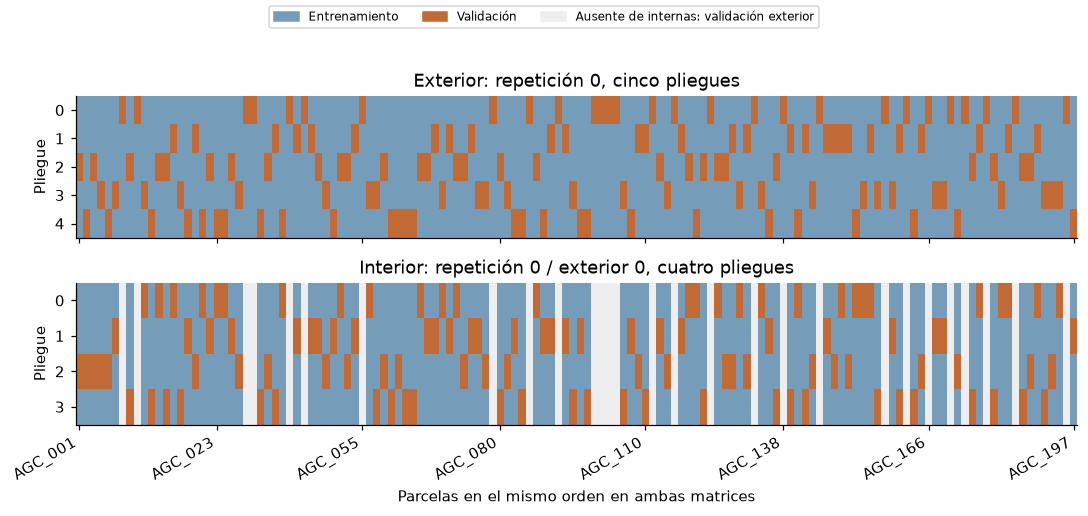

,particiones_externas,pliegues_internos_por_externa,filas,contencion_ok,sin_validacion_externa_en_internas
0,50,[4],22080,True,True


In [9]:
assert resumen_internas["sin_validacion_externa_en_internas"] and resumen_internas["contencion_ok"]
assert internas[["repeticion", "pliegue", "pliegue_interno"]].drop_duplicates().shape[0] == 200
ids138 = tabla138.ID_POLIGONO.tolist()
codigos_roles = {"entrenamiento": 1, "validacion": 2}
matriz_ext = externas.loc[externas.repeticion.eq(0)].assign(valor=lambda d: d.rol.map(codigos_roles)).pivot(
    index="pliegue", columns="ID_POLIGONO", values="valor"
).reindex(columns=ids138)
matriz_int = internas.loc[internas.repeticion.eq(0) & internas.pliegue.eq(0)].assign(
    valor=lambda d: d.rol.map(codigos_roles)
).pivot(index="pliegue_interno", columns="ID_POLIGONO", values="valor").reindex(columns=ids138).fillna(0)
fig, axes = plt.subplots(2, 1, figsize=(10, 4.7), sharex=True)
colores_roles = ListedColormap(["#eeeeee", "#759cb9", "#c16a35"])
for ax, matriz, titulo in [(axes[0], matriz_ext, "Exterior: repetición 0, cinco pliegues"),
                           (axes[1], matriz_int, "Interior: repetición 0 / exterior 0, cuatro pliegues")]:
    ax.imshow(matriz.to_numpy(), cmap=colores_roles, vmin=0, vmax=2, interpolation="nearest", aspect="auto")
    ax.set(title=titulo, ylabel="Pliegue")
    ax.set_yticks(range(len(matriz)), matriz.index.tolist())
ticks = np.linspace(0, 137, 8, dtype=int)
axes[1].set_xticks(ticks, [ids138[i] for i in ticks], rotation=30, ha="right")
axes[1].set_xlabel("Parcelas en el mismo orden en ambas matrices")
fig.legend(handles=[Patch(color="#759cb9", label="Entrenamiento"), Patch(color="#c16a35", label="Validación"),
                    Patch(color="#eeeeee", label="Ausente de internas: validación exterior")],
           loc="upper center", ncol=3, fontsize=8)
fig.tight_layout(rect=(0, 0, 1, .9)); plt.show()
display(pd.DataFrame([resumen_internas]))

**Abrir los IDs apartados.** Buscamos en el CSV la primera validación de AGC_001,
sin mirar su rendimiento. Formamos dos conjuntos de IDs: deben ser disjuntos y
cubrir las 138 parcelas. Después comprobamos que cada interna contiene solo el
entrenamiento de ese exterior. La figura anterior usa exterior 0; este ejemplo
muestra el pliegue donde se aparta AGC_001, identificado en la salida.

Un **hiperparámetro** es una regla fijada antes del ajuste, como el número de vecinos.
Si lo comparáramos para elegirlo, usaríamos las internas; aquí no elegimos ninguno.

In [10]:
asignacion_visible = externas.loc[externas.ID_POLIGONO.eq("AGC_001") &
                                   externas.rol.eq("validacion")].sort_values(["repeticion", "pliegue"]).iloc[0]
r_visible, f_visible = int(asignacion_visible.repeticion), int(asignacion_visible.pliegue)
exterior_visible = externas.loc[externas.repeticion.eq(r_visible) & externas.pliegue.eq(f_visible)]
ids_train_visible = set(exterior_visible.loc[exterior_visible.rol.eq("entrenamiento"), "ID_POLIGONO"])
ids_val_visible = set(exterior_visible.loc[exterior_visible.rol.eq("validacion"), "ID_POLIGONO"])
assert ids_train_visible.isdisjoint(ids_val_visible)
assert ids_train_visible | ids_val_visible == set(tabla138.ID_POLIGONO)
assert "AGC_001" in ids_val_visible and "AGC_001" not in ids_train_visible
_, _, indices_train_motor, indices_val_motor = next(p for p in particiones if p[:2] == (r_visible, f_visible))
assert set(tabla138.iloc[indices_train_motor].ID_POLIGONO) == ids_train_visible
assert set(tabla138.iloc[indices_val_motor].ID_POLIGONO) == ids_val_visible
controles_internos_visibles = []
internas_visibles = internas.loc[internas.repeticion.eq(r_visible) & internas.pliegue.eq(f_visible)]
for numero, grupo in internas_visibles.groupby("pliegue_interno"):
    tr_interno = set(grupo.loc[grupo.rol.eq("entrenamiento"), "ID_POLIGONO"])
    va_interno = set(grupo.loc[grupo.rol.eq("validacion"), "ID_POLIGONO"])
    assert tr_interno.isdisjoint(va_interno)
    assert tr_interno | va_interno == ids_train_visible
    assert set(grupo.ID_POLIGONO).isdisjoint(ids_val_visible)
    controles_internos_visibles.append({"interna": numero, "entrenan": len(tr_interno),
                                         "se validan": len(va_interno), "del exterior excluidas": len(ids_val_visible)})
print("AGC_001 apartada: repetición", r_visible, "pliegue", f_visible,
      "| Entrenan:", len(ids_train_visible), "| Se validan:", len(ids_val_visible))
display(exterior_visible.loc[exterior_visible.ID_POLIGONO.eq("AGC_001")])
display(pd.DataFrame(controles_internos_visibles))

AGC_001 apartada: repetición 0 pliegue 2 | Entrenan: 110 | Se validan: 28


,repeticion,pliegue,rol,ID_POLIGONO
386,0,2,validacion,AGC_001


,interna,entrenan,se validan,del exterior excluidas
0,0,82,28,28
1,1,82,28,28
2,2,83,27,28
3,3,83,27,28


**Resultado y límite.** La contención queda comprobada sin usar valores de rendimiento.
Una estructura anidada limita fuga durante la selección, pero no borra el uso adaptativo
previo de estos datos ni transforma esta reconstrucción retrospectiva en un estudio confirmatorio.

## 5. Seguir AGC_001 en un pliegue donde se aparta

**Qué comprobamos.** Buscamos su primera validación guardada, retiramos la parcela
antes de calcular medias y mostramos el entrenamiento que sustenta la referencia municipal.
GLOBAL aprende la media del entrenamiento; MUN su media municipal, con GLOBAL si el
municipio no existe allí. MIX combina **0.5 MUN + 0.5 IDW**: 20 vecinos, potencia 2,
distancia mínima 1 m, sin buscar parámetros mejores.
En el mensaje del control de invariancia, «municipio nuevo utiliza GLOBAL» se refiere
a **MUN**, no a MIX completo: la parte IDW permanece.

En IDW, los pesos son proporcionales a **1 / max(distancia, 1 m)²**, normalizados
sobre los vecinos seleccionados. Las distancias usan centroides de área UTM14N.

**Abrir MIX: de vecinos a una predicción.** IDW significa ponderación por distancia
inversa: los centroides cercanos reciben mayor peso. Buscamos los 20 vecinos entre
**todo el entrenamiento**, no solo el municipio. La tabla muestra distancia en m,
peso adimensional y **aporte = peso × rendimiento de entrenamiento**, en t/ha.
Sumamos los aportes y mezclamos con MUN. IDW es un componente, no una cuarta
referencia evaluada aquí.

Conservamos el orden de entrenamiento y `np.argsort`. El piso de 1 m evita dividir
por cero; incluso una distancia cero usa ese piso, no una regla nueva de copiar la
etiqueta del vecino. Calculamos primero y después contrastamos con la función.
No abrimos el rendimiento de AGC_001 para construir esta predicción.

In [11]:
entrenamiento_visible = tabla138.loc[tabla138.ID_POLIGONO.isin(ids_train_visible)].copy()
objetivo_visible = tabla138.loc[tabla138.ID_POLIGONO.eq("AGC_001"),
                                ["ID_POLIGONO", "Municipio", "x_m", "y_m"]].copy()
assert "RENDIMIENTO_T_HA" not in objetivo_visible
y_train_visible = entrenamiento_visible.RENDIMIENTO_T_HA.to_numpy(dtype=float)
global_visible = y_train_visible.sum() / len(y_train_visible)
municipio_visible = objetivo_visible.iloc[0].Municipio
y_municipio_visible = entrenamiento_visible.loc[entrenamiento_visible.Municipio.eq(municipio_visible),
                                                "RENDIMIENTO_T_HA"].to_numpy(dtype=float)
mun_visible = y_municipio_visible.sum() / len(y_municipio_visible) if len(y_municipio_visible) else global_visible
receta_mix_visible = CONFIG["referencias"]["MIX"]
xy_train_visible = entrenamiento_visible[["x_m", "y_m"]].to_numpy(dtype=float)
xy_objetivo_visible = objetivo_visible[["x_m", "y_m"]].to_numpy(dtype=float)[0]
distancias_visibles = np.linalg.norm(xy_train_visible - xy_objetivo_visible, axis=1)
vecinos_idx = np.argsort(distancias_visibles)[:min(receta_mix_visible["idw_k"], len(entrenamiento_visible))]
distancias_vecinos = distancias_visibles[vecinos_idx]
pesos_brutos_visibles = 1 / np.maximum(distancias_vecinos, receta_mix_visible["distancia_minima_m"]) ** receta_mix_visible["idw_potencia"]
pesos_visibles = pesos_brutos_visibles / pesos_brutos_visibles.sum()
aportes_visibles = pesos_visibles * y_train_visible[vecinos_idx]
idw_visible = aportes_visibles.sum()
mix_visible = (receta_mix_visible["peso_municipal"] * mun_visible +
               (1 - receta_mix_visible["peso_municipal"]) * idw_visible)
predicciones_visibles = {"GLOBAL": global_visible, "MUN": mun_visible, "MIX": mix_visible}
vecinos_visibles = entrenamiento_visible.iloc[vecinos_idx][["ID_POLIGONO", "Municipio", "RENDIMIENTO_T_HA"]].copy()
vecinos_visibles["distancia_m"] = distancias_vecinos
vecinos_visibles["peso"] = pesos_visibles
vecinos_visibles["aporte_t_ha"] = aportes_visibles
motor_visible = validacion.predecir_referencias(entrenamiento_visible, objetivo_visible)
for nombre, valor in predicciones_visibles.items():
    np.testing.assert_allclose(valor, motor_visible[nombre][0], atol=1e-12, rtol=0)
np.testing.assert_allclose(pesos_visibles.sum(), 1., atol=1e-12, rtol=0)
display(vecinos_visibles.reset_index(drop=True).round(6))
display(pd.DataFrame([{"referencia": nombre, "cálculo visible (t/ha)": valor,
                       "motor (t/ha)": motor_visible[nombre][0]} for nombre, valor in predicciones_visibles.items()]).round(6))
print("GLOBAL usa", len(y_train_visible), "etiquetas; MUN usa", len(y_municipio_visible),
      "| Componente IDW:", idw_visible)

,ID_POLIGONO,Municipio,RENDIMIENTO_T_HA,distancia_m,peso,aporte_t_ha
0,AGC_046,Calpulalpan,3.0,1422.785517,0.231293,0.693880
1,AGC_098,Calpulalpan,3.0,1802.730550,0.144072,0.432217
2,AGC_114,Calpulalpan,3.0,1965.305189,0.121222,0.363667
3,AGC_141,Calpulalpan,3.5,2588.303603,0.069889,0.244613
4,AGC_054,Calpulalpan,2.5,2732.916495,0.062689,0.156722
5,AGC_157,Calpulalpan,3.0,2739.731658,0.062377,0.187132
6,AGC_163,Calpulalpan,3.0,2839.272612,0.058080,0.174241
7,AGC_145,Calpulalpan,3.5,3534.966990,0.037469,0.131141
8,AGC_123,Calpulalpan,2.5,3999.892809,0.029265,0.073162
9,AGC_138,Calpulalpan,2.5,4641.695717,0.021731,0.054329


,referencia,cálculo visible (t/ha),motor (t/ha)
0,GLOBAL,3.956818,3.956818
1,MUN,2.928571,2.928571
2,MIX,2.955055,2.955055


GLOBAL usa 110 etiquetas; MUN usa 21 | Componente IDW: 2.9815394025651196


In [12]:
PARCELA = "AGC_001"
primer_validacion = externas.loc[externas.ID_POLIGONO.eq(PARCELA) & externas.rol.eq("validacion")].sort_values(
    ["repeticion", "pliegue"]
).iloc[0]
r_demo, f_demo = int(primer_validacion.repeticion), int(primer_validacion.pliegue)
_, _, tr_demo, va_demo = next(p for p in particiones if p[:2] == (r_demo, f_demo))
a_demo = tabla138.iloc[tr_demo].copy()
t_demo = tabla138.iloc[va_demo].drop(columns="RENDIMIENTO_T_HA").copy()
assert PARCELA not in set(a_demo.ID_POLIGONO) and PARCELA in set(t_demo.ID_POLIGONO)
pred_demo = validacion.predecir_referencias(a_demo, t_demo)
posicion_demo = t_demo.ID_POLIGONO.tolist().index(PARCELA)
municipio_demo = t_demo.iloc[posicion_demo].Municipio
entrenamiento_municipal = a_demo.loc[a_demo.Municipio.eq(municipio_demo)]
media_global_demo = float(a_demo.RENDIMIENTO_T_HA.mean())
media_municipal_demo = float(entrenamiento_municipal.RENDIMIENTO_T_HA.mean()) if len(entrenamiento_municipal) else media_global_demo
print("Parcela apartada:", PARCELA, "| Repetición:", r_demo, "| Pliegue:", f_demo)
print("Entrenamiento:", len(a_demo), "| Validación:", len(t_demo), "| Municipio:", municipio_demo)
display(entrenamiento_municipal[["ID_POLIGONO", "Municipio", "RENDIMIENTO_T_HA"]])
assert np.isclose(pred_demo["GLOBAL"][posicion_demo], media_global_demo, atol=1e-12, rtol=0)
assert np.isclose(pred_demo["MUN"][posicion_demo], media_municipal_demo, atol=1e-12, rtol=0)
observado_demo = float(tabla138.set_index("ID_POLIGONO").loc[PARCELA, "RENDIMIENTO_T_HA"])
display(pd.DataFrame([{"referencia": nombre, "predicho_t_ha": valores[posicion_demo],
                       "observado_t_ha": observado_demo, "error_t_ha": valores[posicion_demo] - observado_demo}
                      for nombre, valores in pred_demo.items()]).round(6))

Parcela apartada: AGC_001 | Repetición: 0 | Pliegue: 2
Entrenamiento: 110 | Validación: 28 | Municipio: Calpulalpan


,ID_POLIGONO,Municipio,RENDIMIENTO_T_HA
15,AGC_019,Calpulalpan,3.0
19,AGC_023,Calpulalpan,3.0
28,AGC_040,Calpulalpan,3.0
32,AGC_046,Calpulalpan,3.0
38,AGC_054,Calpulalpan,2.5
49,AGC_068,Calpulalpan,2.5
54,AGC_074,Calpulalpan,2.5
67,AGC_098,Calpulalpan,3.0
68,AGC_099,Calpulalpan,3.5
72,AGC_103,Calpulalpan,3.0


,referencia,predicho_t_ha,observado_t_ha,error_t_ha
0,GLOBAL,3.956818,3.5,0.456818
1,MUN,2.928571,3.5,-0.571429
2,MIX,2.955055,3.5,-0.544945


In [13]:
# Control sintético y control real: modificar etiquetas de validación no cambia predicciones.
a_sintetico = pd.DataFrame({"Municipio": ["A", "A", "B"], "x_m": [0., 3., 9.],
                            "y_m": [0., 0., 0.], "RENDIMIENTO_T_HA": [1., 5., 8.]})
t_sintetico = pd.DataFrame({"Municipio": ["A", "N"], "x_m": [1., 8.], "y_m": [0., 0.],
                            "RENDIMIENTO_T_HA": [999., 999.]})
antes = validacion.predecir_referencias(a_sintetico, t_sintetico)
despues = validacion.predecir_referencias(a_sintetico, t_sintetico.assign(RENDIMIENTO_T_HA=-999.))
for nombre in antes:
    np.testing.assert_array_equal(antes[nombre], despues[nombre])
np.testing.assert_allclose(antes["MUN"], [3., 14. / 3.], atol=1e-12, rtol=0)
t_modificado = t_demo.assign(RENDIMIENTO_T_HA=12345.)
for nombre, prediccion in validacion.predecir_referencias(a_demo, t_modificado).items():
    np.testing.assert_array_equal(prediccion, pred_demo[nombre])
print("Invariancia a etiquetas de validación: comprobada; municipio nuevo utiliza GLOBAL.")

Invariancia a etiquetas de validación: comprobada; municipio nuevo utiliza GLOBAL.


**Decisión y límite.** El observado se utiliza después de predecir para calcular error.
La receta municipal nunca incorpora a la parcela apartada. Estas comprobaciones
demuestran una propiedad del cálculo; no certifican por sí solas ausencia de toda fuga
ni que la ubicación mantenga su utilidad en otras regiones o campañas.

## 6. Construir predicciones fuera de muestra verificables

**Qué comprobamos y cómo.** Repetimos las tres recetas en las 50 particiones externas,
guardando en memoria modelo, repetición, pliegue, ID, observado y predicho, media y
tamaños del entrenamiento. La bandera municipal usa únicamente pertenencia de grupos.

Cada referencia genera **138 × 10 = 1,380 predicciones OOF**; tres referencias suman
**4,140** filas. Siguen siendo **138 parcelas**, no 1,380 casos independientes.

**OOF** (*out-of-fold*) significa fuera del pliegue que ajustó la referencia:
conocemos la etiqueta para evaluar, pero no la usamos en ese ajuste. No significa
fuera de todo el desarrollo ni borra decisiones adaptativas anteriores.

In [14]:
oof = validacion.construir_oof(tabla138, externas)
resumen_oof = validacion.validar_oof(oof, externas)
assert len(oof) == 4140 and oof.groupby("modelo").size().eq(1380).all()
assert oof.ID_POLIGONO.nunique() == 138
display(pd.DataFrame([resumen_oof]))
display(oof.loc[oof.ID_POLIGONO.eq(PARCELA) & oof.repeticion.eq(r_demo),
                ["modelo", "repeticion", "pliegue", "ID_POLIGONO", "observado", "predicho",
                 "ref_media_entrenamiento", "n_entrenamiento", "n_validacion", "municipio_visto"]].round(6))

,modelos,filas_por_modelo,filas,parcelas,claves_completas,valores_finitos
0,"[GLOBAL, MUN, MIX]",1380,4140,138,True,True


,modelo,repeticion,pliegue,ID_POLIGONO,observado,predicho,ref_media_entrenamiento,n_entrenamiento,n_validacion,municipio_visto
168,GLOBAL,0,2,AGC_001,3.5,3.956818,3.956818,110,28,True
196,MUN,0,2,AGC_001,3.5,2.928571,3.956818,110,28,True
224,MIX,0,2,AGC_001,3.5,2.955055,3.956818,110,28,True


**Abrir una fila OOF.** Para AGC_001 unimos la predicción ya calculada con su
observado, únicamente para medir el error. La clave es **modelo + repetición +
pliegue + ID**. Construimos sus tres filas y las contrastamos con `construir_oof`.
Después contamos sus diez apariciones por referencia: es la misma parcela con
distintos entrenamientos, no diez parcelas nuevas. Esta demostración no alimenta
la tabla OOF usada para puntuar.

In [15]:
assert (r_demo, f_demo) == (r_visible, f_visible)
filas_oof_visibles = pd.DataFrame([
    {"modelo": nombre, "repeticion": r_visible, "pliegue": f_visible, "ID_POLIGONO": "AGC_001",
     "observado": observado_demo, "predicho": valor}
    for nombre, valor in predicciones_visibles.items()
])
claves_visibles = ["modelo", "repeticion", "pliegue", "ID_POLIGONO"]
filas_oof_motor = oof.loc[oof.ID_POLIGONO.eq("AGC_001") & oof.repeticion.eq(r_visible) &
                          oof.pliegue.eq(f_visible), filas_oof_visibles.columns]
pd.testing.assert_frame_equal(filas_oof_visibles.set_index(claves_visibles).sort_index(),
                               filas_oof_motor.set_index(claves_visibles).sort_index(),
                               check_exact=False, atol=1e-12, rtol=0)
display(filas_oof_visibles.round(6))
apariciones_visibles = oof.groupby(["modelo", "ID_POLIGONO"]).size()
assert apariciones_visibles.eq(10).all()
display(apariciones_visibles.xs("AGC_001", level="ID_POLIGONO").rename("predicciones de esta misma parcela"))

,modelo,repeticion,pliegue,ID_POLIGONO,observado,predicho
0,GLOBAL,0,2,AGC_001,3.5,3.956818
1,MUN,0,2,AGC_001,3.5,2.928571
2,MIX,0,2,AGC_001,3.5,2.955055


modelo
GLOBAL    10
MIX       10
MUN       10
Name: predicciones de esta misma parcela, dtype: int64

**Resultado y límite.** Las claves corresponden exactamente a las validaciones
guardadas. Las repeticiones comparten parcelas y entrenamientos; no permiten tratar
sus resultados como réplicas independientes de un experimento de campo.

## 7. Puntuar los errores originales: FULL138

**Qué comprobamos.** Sobre las 1,380 predicciones de cada referencia calculamos:

- **RMSE = √media((predicho − observado)²)**, en t/ha.
- **MAE = media(|predicho − observado|)**, en t/ha.
- **R² = 1 − Σ(error²) / Σ(observado − media evaluada)²**, adimensional.

La media del denominador de R² pertenece al conjunto evaluado. No promediamos
primero las diez predicciones de una parcela ni mezclamos medias de métricas de pliegues.
FULL138 evalúa todas las parcelas etiquetadas con la agregación histórica agrupada.

,modelo,escenario,n_parcelas,n_oof,RMSE,MAE,R2
0,GLOBAL,FULL138,138,1380,0.854426,0.753994,-0.015043
1,MUN,FULL138,138,1380,0.511757,0.335394,0.635865
2,MIX,FULL138,138,1380,0.493845,0.341711,0.660908


R² estándar GLOBAL: -0.015042909859176223
Habilidad de GLOBAL frente a su media de entrenamiento: 0.0


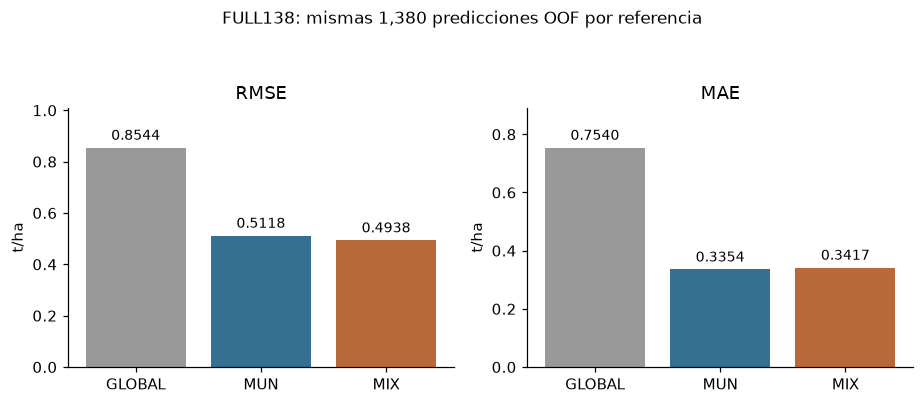

In [16]:
metricas_full = validacion.resumen_metricas(oof, escenario="FULL138")
assert metricas_full.n_parcelas.eq(138).all() and metricas_full.n_oof.eq(1380).all()
display(metricas_full.round(6))
global_oof = oof.loc[oof.modelo.eq("GLOBAL")]
sse_global = float(((global_oof.predicho - global_oof.observado) ** 2).sum())
sse_media_train = float(((global_oof.ref_media_entrenamiento - global_oof.observado) ** 2).sum())
habilidad_vs_media_train = 1 - sse_global / sse_media_train
assert np.isclose(habilidad_vs_media_train, 0., atol=1e-12, rtol=0)
assert metricas_full.set_index("modelo").loc["GLOBAL", "R2"] < 0
assert metricas_full.sort_values("RMSE").modelo.tolist() == metricas_full.sort_values("R2", ascending=False).modelo.tolist()
print("R² estándar GLOBAL:", metricas_full.set_index("modelo").loc["GLOBAL", "R2"])
print("Habilidad de GLOBAL frente a su media de entrenamiento:", habilidad_vs_media_train)
orden_refs = ["GLOBAL", "MUN", "MIX"]
colores = ["#999999", "#356f91", "#b9683a"]
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.7))
valores = metricas_full.set_index("modelo").loc[orden_refs]
for ax, metrica in zip(axes, ["RMSE", "MAE"]):
    barras = ax.bar(orden_refs, valores[metrica], color=colores)
    ax.bar_label(barras, fmt="%.4f", padding=3, fontsize=9)
    ax.set(ylabel="t/ha", title=metrica, ylim=(0, float(valores[metrica].max()) * 1.18))
fig.suptitle("FULL138: mismas 1,380 predicciones OOF por referencia", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, .92)); plt.show()

**Abrir las métricas: errores, no una función sin explicación.** Conservamos las
1,380 filas de cada referencia. De cada error salen su valor absoluto y cuadrado;
sus medias producen MAE y RMSE. Para R² calculamos SSE (suma de error cuadrático)
y SST (variación de los observados respecto a su propia media evaluada).
La tabla muestra los primeros errores de MIX; la suma usa **todas** sus filas.
Si SST ≤ 10⁻¹², la receta devuelve NaN: por ejemplo, evaluar diez predicciones
de una sola parcela no define R² porque su observado no cambia.

In [17]:
metricas_visibles = []
for nombre, grupo in oof.groupby("modelo", sort=False):
    y_visible = grupo.observado.to_numpy(dtype=float)
    p_visible = grupo.predicho.to_numpy(dtype=float)
    errores_visibles = p_visible - y_visible
    sse_visible = (errores_visibles ** 2).sum()
    sst_visible = ((y_visible - y_visible.mean()) ** 2).sum()
    metricas_visibles.append({"modelo": nombre, "n_oof": len(grupo),
                              "RMSE": np.sqrt((errores_visibles ** 2).mean()),
                              "MAE": np.abs(errores_visibles).mean(),
                              "R2": 1 - sse_visible / sst_visible if sst_visible > 1e-12 else np.nan})
metricas_visibles = pd.DataFrame(metricas_visibles).set_index("modelo")
control_metricas_visibles = metricas_full.set_index("modelo").loc[metricas_visibles.index]
np.testing.assert_allclose(metricas_visibles[["RMSE", "MAE", "R2"]].to_numpy(dtype=float),
                           control_metricas_visibles[["RMSE", "MAE", "R2"]].to_numpy(dtype=float),
                           atol=1e-12, rtol=0)
assert metricas_visibles.n_oof.eq(control_metricas_visibles.n_oof).all()
errores_muestra = oof.loc[oof.modelo.eq("MIX"), ["repeticion", "pliegue", "ID_POLIGONO", "observado", "predicho"]].head(6).copy()
errores_muestra["error_t_ha"] = errores_muestra.predicho - errores_muestra.observado
errores_muestra["absoluto_t_ha"] = errores_muestra.error_t_ha.abs()
errores_muestra["cuadrado_t2_ha2"] = errores_muestra.error_t_ha ** 2
display(errores_muestra.round(6))
display(metricas_visibles.round(6))

,repeticion,pliegue,ID_POLIGONO,observado,predicho,error_t_ha,absoluto_t_ha,cuadrado_t2_ha2
56,0,0,AGC_008,4.55,4.413885,-0.136115,0.136115,0.018527
57,0,0,AGC_010,4.10,4.390691,0.290691,0.290691,0.084501
58,0,0,AGC_033,4.47,4.623586,0.153586,0.153586,0.023589
59,0,0,AGC_034,2.00,3.277228,1.277228,1.277228,1.631311
60,0,0,AGC_041,2.50,3.251011,0.751011,0.751011,0.564017
61,0,0,AGC_045,4.10,4.511817,0.411817,0.411817,0.169593


,n_oof,RMSE,MAE,R2
modelo,,,,
GLOBAL,1380,0.854426,0.753994,-0.015043
MUN,1380,0.511757,0.335394,0.635865
MIX,1380,0.493845,0.341711,0.660908


**Por qué no promediamos antes de puntuar.** Este ejemplo es **inventado**:
dos parcelas, dos repeticiones y errores de +1/−1. Al promediar sus predicciones,
esos errores se cancelan y el resultado cambia. Promediar sería evaluar otra
regla de predicción, no el mismo procedimiento histórico. No usamos este ejemplo
para afirmar cuánto cambiarían las métricas reales ni para crear un candidato.

In [18]:
ejemplo_promedios = pd.DataFrame({"parcela": ["A", "B", "A", "B"], "repeticion": [0, 0, 1, 1],
                                  "observado": [1., 3., 1., 3.], "predicho": [0., 4., 2., 2.]})
errores_sinteticos = ejemplo_promedios.predicho - ejemplo_promedios.observado
rmse_antes_promediar = np.sqrt((errores_sinteticos ** 2).mean())
promedios_sinteticos = ejemplo_promedios.groupby("parcela").agg(observado=("observado", "first"),
                                                                predicho=("predicho", "mean"))
rmse_despues_promediar = np.sqrt(((promedios_sinteticos.predicho - promedios_sinteticos.observado) ** 2).mean())
assert rmse_antes_promediar == 1. and rmse_despues_promediar == 0.
display(ejemplo_promedios)
display(promedios_sinteticos)
print("RMSE de los errores individuales:", rmse_antes_promediar,
      "| RMSE después de cancelar errores al promediar:", rmse_despues_promediar)

,parcela,repeticion,observado,predicho
0,A,0,1.0,0.0
1,B,0,3.0,4.0
2,A,1,1.0,2.0
3,B,1,3.0,2.0


,observado,predicho
parcela,,
A,1.0,1.0
B,3.0,3.0


RMSE de los errores individuales: 1.0 | RMSE después de cancelar errores al promediar: 0.0


**Interpretación.** GLOBAL puede tener R² estándar negativo aunque su habilidad
frente a la media del entrenamiento valga cero por construcción: son denominadores
distintos. Con los mismos observados y agregación agrupada, menor RMSE equivale a
mayor R² porque su denominador es fijo; no son dos evidencias predictivas independientes.
MAE sí puede preferir MUN mientras RMSE prefiere MIX. Ese intercambio no selecciona
un modelo final ni resuelve el criterio oficial de FIRA.

## 8. Separar municipios vistos: SEEN135

**Qué comprobamos y cómo.** SEEN conserva las mismas predicciones OOF y todos los
entrenamientos originales, pero puntúa únicamente validaciones cuyo municipio
estaba presente en entrenamiento. La máscara se define sin rendimiento y es igual
para las tres referencias. No reajustamos sobre 135 parcelas ni cambiamos FULL138.

Revisamos también cobertura municipal de las 59 parcelas ocultas para describir
su escenario, sin generar predicciones. Compartir municipio no garantiza compartir
dificultad ni tener evidencia suficiente para una parcela particular.

In [19]:
metricas_seen = validacion.resumen_metricas(oof, escenario="SEEN135")
oof_seen = oof.loc[oof.municipio_visto]
assert oof_seen.ID_POLIGONO.nunique() == 135
assert metricas_seen.n_parcelas.eq(135).all() and metricas_seen.n_oof.eq(1350).all()
display(metricas_seen.round(6))
removidas = oof.loc[oof.modelo.eq("GLOBAL") & ~oof.municipio_visto]
display(removidas.groupby(["ID_POLIGONO", "Municipio"]).size().rename("OOF excluidas por referencia").reset_index())
assert set(removidas.ID_POLIGONO) == {"AGC_047", "AGC_048", "AGC_164"}
assert len(removidas) == 30
conteos_municipales = pd.concat([
    tabla138.groupby("Municipio").size().rename("etiquetadas"),
    ocultas.groupby("Municipio").size().rename("ocultas"),
    removidas.groupby("Municipio").size().rename("OOF excluidas por referencia"),
], axis=1).fillna(0).astype(int).reset_index()
display(conteos_municipales)
assert ocultas.Municipio.isin(set(tabla138.Municipio)).all()
print("Ocultas con municipio representado en las etiquetas:", len(ocultas), "de 59")
display(meta.loc[meta.ID_POLIGONO.isin(["AGC_048", "AGC_120"]), ["ID_POLIGONO", "Municipio", "CONJUNTO"]])

,modelo,escenario,n_parcelas,n_oof,RMSE,MAE,R2
0,GLOBAL,SEEN135,135,1350,0.849706,0.749176,-0.015837
1,MUN,SEEN135,135,1350,0.493404,0.321274,0.657475
2,MIX,SEEN135,135,1350,0.487197,0.334215,0.666039


,ID_POLIGONO,Municipio,OOF excluidas por referencia
0,AGC_047,Tepeapulco,10
1,AGC_048,Nanacamilpa de Mariano Arista,10
2,AGC_164,Apan,10


,Municipio,etiquetadas,ocultas,OOF excluidas por referencia
0,Almoloya,10,4,0
1,Apan,1,0,10
2,Calpulalpan,30,14,0
3,Chignahuapan,71,29,0
4,Cuautepec de Hinojosa,5,4,0
5,Emiliano Zapata,3,0,0
6,Nanacamilpa de Mariano Arista,1,1,10
7,Singuilucan,16,7,0
8,Tepeapulco,1,0,10


Ocultas con municipio representado en las etiquetas: 59 de 59


,ID_POLIGONO,Municipio,CONJUNTO
47,AGC_048,Nanacamilpa de Mariano Arista,ENTRENAMIENTO
119,AGC_120,Nanacamilpa de Mariano Arista,PREDICCION


**Abrir la máscara, sin elegir por error.** Comparamos la primera validación de
AGC_001 y la de **AGC_048**, la única etiqueta de Nanacamilpa. Solo contamos otras
etiquetas de su municipio en el entrenamiento: no miramos sus valores ni el error
para incluirlas en SEEN. Contrastamos esta pertenencia con la bandera OOF.

Si falta el municipio, **MUN** vuelve a GLOBAL; **MIX** conserva su componente
IDW, por lo que no tiene que ser igual a GLOBAL. FULL138 conserva esos casos;
SEEN135 los excluye al puntuar, sin reentrenar. Que la entrega tenga municipios
representados no garantiza que este filtro estime su error.

In [20]:
pertenencias_visibles = []
for id_mascara in ["AGC_001", "AGC_048"]:
    fila_asignada = externas.loc[externas.ID_POLIGONO.eq(id_mascara) & externas.rol.eq("validacion")].sort_values(
        ["repeticion", "pliegue"]).iloc[0]
    r_mascara, f_mascara = int(fila_asignada.repeticion), int(fila_asignada.pliegue)
    ids_mascara_train = set(externas.loc[externas.repeticion.eq(r_mascara) & externas.pliegue.eq(f_mascara)
                                        & externas.rol.eq("entrenamiento"), "ID_POLIGONO"])
    municipio_mascara = tabla138.set_index("ID_POLIGONO").loc[id_mascara, "Municipio"]
    n_municipales = int((tabla138.ID_POLIGONO.isin(ids_mascara_train) & tabla138.Municipio.eq(municipio_mascara)).sum())
    visto_visible = n_municipales > 0
    filas_mascara_motor = oof.loc[oof.ID_POLIGONO.eq(id_mascara) & oof.repeticion.eq(r_mascara) & oof.pliegue.eq(f_mascara)]
    assert len(filas_mascara_motor) == 3 and filas_mascara_motor.municipio_visto.eq(visto_visible).all()
    pertenencias_visibles.append({"parcela": id_mascara, "municipio": municipio_mascara,
                                   "repetición": r_mascara, "pliegue": f_mascara,
                                   "etiquetas municipales en entrenamiento": n_municipales,
                                   "municipio visto": visto_visible,
                                   "entra en FULL138": True, "entra en SEEN135": visto_visible})
display(pd.DataFrame(pertenencias_visibles))
display(pd.concat([metricas_full, metricas_seen])[['modelo', 'escenario', 'n_parcelas', 'n_oof']])

,parcela,municipio,repetición,pliegue,etiquetas municipales en entrenamiento,municipio visto,entra en FULL138,entra en SEEN135
0,AGC_001,Calpulalpan,0,2,21,True,True,True
1,AGC_048,Nanacamilpa de Mariano Arista,0,3,0,False,True,False


,modelo,escenario,n_parcelas,n_oof
0,GLOBAL,FULL138,138,1380
1,MUN,FULL138,138,1380
2,MIX,FULL138,138,1380
0,GLOBAL,SEEN135,135,1350
1,MUN,SEEN135,135,1350
2,MIX,SEEN135,135,1350


**Resultado y límite.** Las 30 exclusiones por referencia corresponden a AGC_047
(Tepeapulco), AGC_048 (Nanacamilpa) y AGC_164 (Apan), diez veces cada una.
Las 59 ocultas tienen municipios representados entre las etiquetas, pero Nanacamilpa
tiene una sola etiqueta, AGC_048. Cuando esa parcela se aparta, no queda entrenamiento
municipal; AGC_120, oculta del mismo municipio, no tiene una situación OOF equivalente.
SEEN135 es un escenario de lectura adicional, no una garantía sobre el error final.

## 9. Comparar repeticiones de forma pareada y descriptiva

**Qué comprobamos.** MUN y MIX se puntúan sobre los mismos IDs de cada repetición.
Restamos métricas MIX−MUN para observar el intercambio entre error cuadrático y
absoluto. Un valor negativo indica menor error de MIX en esa repetición.

Las diez diferencias son descriptivas: no calculamos pruebas t, p-valores ni intervalos
de confianza tratando pliegues o repeticiones como observaciones independientes.

,MIX_menos_MUN_RMSE,MIX_menos_MUN_MAE
repeticion,,
0,-0.026749,0.001443
1,-0.021644,0.005660
2,-0.016180,0.010445
3,-0.012982,0.014131
4,-0.024351,0.003418
5,-0.020691,0.001621
6,-0.008011,0.007852
7,-0.021175,0.005731
8,-0.011040,0.003522


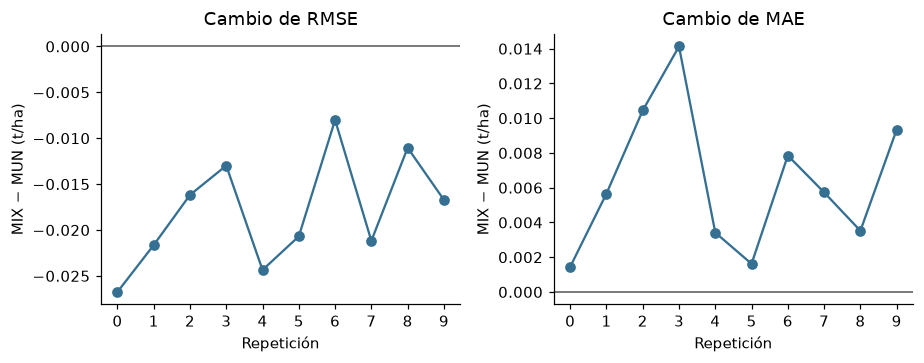

Repeticiones con menor RMSE de MIX: 10 de 10
Repeticiones con menor MAE de MIX: 0 de 10


In [21]:
metricas_repeticion = validacion.por_repeticion(oof, escenario="FULL138")
pares_rmse = metricas_repeticion.pivot(index="repeticion", columns="modelo", values="RMSE")
pares_mae = metricas_repeticion.pivot(index="repeticion", columns="modelo", values="MAE")
diferencias_pareadas = pd.DataFrame({"MIX_menos_MUN_RMSE": pares_rmse.MIX - pares_rmse.MUN,
                                     "MIX_menos_MUN_MAE": pares_mae.MIX - pares_mae.MUN})
display(diferencias_pareadas.round(6))
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.4))
for ax, columna, titulo in zip(axes, diferencias_pareadas.columns, ["Cambio de RMSE", "Cambio de MAE"]):
    ax.axhline(0, color="#555555", linewidth=1)
    ax.plot(diferencias_pareadas.index, diferencias_pareadas[columna], "o-", color="#356f91")
    ax.set(title=titulo, xlabel="Repetición", ylabel="MIX − MUN (t/ha)")
    ax.set_xticks(range(10))
fig.tight_layout(); plt.show()
print("Repeticiones con menor RMSE de MIX:", int(diferencias_pareadas.MIX_menos_MUN_RMSE.lt(0).sum()), "de 10")
print("Repeticiones con menor MAE de MIX:", int(diferencias_pareadas.MIX_menos_MUN_MAE.lt(0).sum()), "de 10")

**Decisión y límite.** La consistencia ayuda a describir el intercambio, pero no basta
para afirmar significancia o seleccionar una solución oficial. Este cuaderno no vuelve
a puntuar las rondas de experimentos ni modifica sus criterios de avance.

## 10. Reproducir predicciones y métricas históricas

**Qué comprobamos y por qué.** Después de recalcular abrimos los controles de salida
de la integración del 21/09/2026. Se validan sus bytes y SHA-256; el contraste exige
claves OOF, observados y tamaños exactos, con tolerancia absoluta **10⁻⁸ t/ha** para
predicciones y medias de entrenamiento. Las métricas agrupadas también se contrastan.

Los nombres descriptivos históricos se corresponden aquí con GLOBAL, MUN y MIX.
La referencia histórica IDW sola se conserva en el archivo de control, pero no forma
parte de las tres referencias reconstruidas en este cuaderno.

In [22]:
oof_control = leer_insumo("oof_historico", "control_de_salida")
metricas_control = leer_insumo("metricas_historicas", "control_de_salida")
tol_control = CONFIG["evaluacion"]["tol_reproduccion_predicciones_t_ha"]
contraste_oof = validacion.comparar_oof(oof, oof_control, tolerancia=tol_control)
assert contraste_oof.coincide.all()
display(contraste_oof)
metricas_control = metricas_control.loc[metricas_control.modelo.isin(validacion.ALIAS_HISTORICOS_03)].copy()
metricas_control["modelo"] = metricas_control.modelo.map(validacion.ALIAS_HISTORICOS_03)
metricas_control = metricas_control.set_index("modelo")
actuales = metricas_full.set_index("modelo").loc[metricas_control.index]
assert actuales.n_parcelas.eq(metricas_control.n_parcelas).all()
assert actuales.n_oof.eq(metricas_control.n_oof).all()
contraste_metricas = pd.DataFrame([
    {"modelo": modelo, "metrica": metrica,
     "diferencia_absoluta": abs(actuales.loc[modelo, metrica] - metricas_control.loc[modelo, metrica + "_agrupado"]),
     "unidad": "adimensional" if metrica == "R2" else "t/ha"}
    for modelo in metricas_control.index for metrica in ["RMSE", "MAE", "R2"]
])
assert contraste_metricas.diferencia_absoluta.le(1e-8).all()
display(contraste_metricas)

,modelo,n_oof,max_abs_dif_predicho,max_abs_dif_ref,tolerancia,coincide,sha256_claves
0,GLOBAL,1380,8.881784e-16,8.881784e-16,1.000000e-08,True,4ea15ccd5623d23a0fe33deae716163e7e224a902bf017...
1,MUN,1380,8.881784e-16,8.881784e-16,1.000000e-08,True,4ea15ccd5623d23a0fe33deae716163e7e224a902bf017...
2,MIX,1380,1.032952e-12,8.881784e-16,1.000000e-08,True,4ea15ccd5623d23a0fe33deae716163e7e224a902bf017...


,modelo,metrica,diferencia_absoluta,unidad
0,GLOBAL,RMSE,0.000000e+00,t/ha
1,GLOBAL,MAE,0.000000e+00,t/ha
2,GLOBAL,R2,2.255141e-17,adimensional
3,MUN,RMSE,0.000000e+00,t/ha
4,MUN,MAE,0.000000e+00,t/ha
5,MUN,R2,0.000000e+00,adimensional
6,MIX,RMSE,1.088019e-14,t/ha
7,MIX,MAE,8.937295e-15,t/ha
8,MIX,R2,1.498801e-14,adimensional


**Resultado y límite.** Reproducir estas salidas permite conservar un control común.
No acredita precisión para otras campañas, municipios nuevos o rendimientos ocultos.
Las particiones y la evaluación son herramientas de desarrollo del proyecto, no una
reconstrucción del mecanismo desconocido del split oficial.

## 11. Cierre: controles antes de probar nuevas hipótesis

**Respuesta comprobable.** Reconstruimos tres referencias sobre las mismas parcelas
apartadas, validamos la jerarquía de particiones, distinguimos FULL138 y SEEN135 y
conservamos errores OOF individuales. La celda final comprueba que el ZIP no cambió
y registra lo recalculado. No exporta tablas ni predicciones por defecto.

Una referencia es un control, no una ecuación oficial ni un ganador final. Añadir
variables o un algoritmo complejo no obliga a superar estas referencias; no hacerlo
tampoco demuestra automáticamente un error de extracción. Habrá que comprobar
procedimiento, variables y validación antes de interpretar una nueva hipótesis.

Las operaciones visibles explican vecinos, pesos, filas OOF y métricas; los módulos
plegados repiten las mismas reglas. Las demostraciones no alimentan las predicciones
evaluadas ni seleccionan parámetros nuevos. Sus comprobaciones de cálculo no prueban
causalidad, precisión en las 59 ocultas ni independencia entre repeticiones.

**Siguiente pregunta:** ¿qué cambio concreto merece probarse manteniendo estos
controles y la misma población de comparación? Los experimentos se estudiarán
después, con sus recetas y límites propios, sin anticipar sus resultados aquí.

In [23]:
hash_final = hashlib.sha256(ruta_dataset.read_bytes()).hexdigest()
assert hash_final == hash_inicial == SHA256_DATASET
resumen_referencias = {
    "notebook": "03_referencias_y_validacion", "fecha_adaptacion": "2026-10-07",
    "particiones_originales": "2026-09-20", "integracion_original": "2026-09-21",
    "fecha_ejecucion_utc": FECHA_EJECUCION_UTC,
    "python": platform.python_version(), "sha256_dataset": hash_final,
    "parcelas": int(len(meta)), "etiquetas": int(len(tabla138)), "por_predecir": int(len(ocultas)),
    "repeticiones": int(resumen_externas["repeticiones"]), "pliegues_externos": int(len(particiones)),
    "pliegues_internos": int(internas[["repeticion", "pliegue", "pliegue_interno"]].drop_duplicates().shape[0]),
    "referencias": int(oof.modelo.nunique()), "oof_por_referencia": int(resumen_oof["filas_por_modelo"]),
    "oof_total": int(len(oof)), "parcelas_seen": int(oof_seen.ID_POLIGONO.nunique()),
    "oof_seen_por_referencia": int(oof_seen.groupby("modelo").size().iloc[0]),
    "referencias_reproducidas": bool(contraste_oof.coincide.all() and contraste_metricas.diferencia_absoluta.le(1e-8).all()),
    # Solo evaluación OOF; las demostraciones e invariancias son controles aparte.
    "ajustes_referencia": int(len(particiones) * oof.modelo.nunique()),
    "modelos_nuevos": 0, "hiperparametros_seleccionados": 0,
    "predicciones_finales_generadas": 0, "tablas_exportadas": 0,
    "archivo_original_inalterado": True,
}
zip_fuente.close()
print(json.dumps(resumen_referencias, ensure_ascii=False, indent=2))
print("RESUMEN_REFERENCIAS_03_JSON=" + json.dumps(resumen_referencias, ensure_ascii=False, sort_keys=True))

{
  "notebook": "03_referencias_y_validacion",
  "fecha_adaptacion": "2026-10-07",
  "particiones_originales": "2026-09-20",
  "integracion_original": "2026-09-21",
  "fecha_ejecucion_utc": "2026-10-08T06:46:00.045046+00:00",
  "python": "3.13.13",
  "sha256_dataset": "d74dbaba1764e026da8ce38f7f3476f80523f479a6c141827887e09326061bb5",
  "parcelas": 197,
  "etiquetas": 138,
  "por_predecir": 59,
  "repeticiones": 10,
  "pliegues_externos": 50,
  "pliegues_internos": 200,
  "referencias": 3,
  "oof_por_referencia": 1380,
  "oof_total": 4140,
  "parcelas_seen": 135,
  "oof_seen_por_referencia": 1350,
  "referencias_reproducidas": true,
  "ajustes_referencia": 150,
  "modelos_nuevos": 0,
  "hiperparametros_seleccionados": 0,
  "predicciones_finales_generadas": 0,
  "tablas_exportadas": 0,
  "archivo_original_inalterado": true
}
RESUMEN_REFERENCIAS_03_JSON={"ajustes_referencia": 150, "archivo_original_inalterado": true, "etiquetas": 138, "fecha_adaptacion": "2026-10-07", "fecha_ejecucion_ut

### Fuentes y referencias — APA 7

Equipo AgroCebada. (2026, 20 de septiembre). *Particiones de desarrollo por parcela*
[Trabajo interno]. Identidad externa COD-CV-5x10-20260920, CSV incrustado con SHA-256.

Equipo AgroCebada. (2026, 21 de septiembre). *Integración y conciliación de referencias*
[Trabajo interno]. GLOBAL, MUN, MIX, particiones internas y salidas históricas
identificadas por hash. Adaptación y comprobación del cuaderno: 7 de octubre de 2026.

scikit-learn developers. (s. f.). *Cross-validation: Evaluating estimator performance*.
https://scikit-learn.org/stable/modules/cross_validation.html

scikit-learn developers. (s. f.). *Metrics and scoring: Quantifying the quality of predictions*.
https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics

Cawley, G. C., & Talbot, N. L. C. (2010). On over-fitting in model selection and
subsequent selection bias in performance evaluation. *Journal of Machine Learning
Research, 11*, 2079–2107. https://www.jmlr.org/papers/v11/cawley10a.html

Estas referencias sustentan separación, métricas y límites de selección; no certifican
el mecanismo oficial de partición ni extrapolación a nuevos territorios o campañas.